# All inports

In [1]:
# ---------------------------------------------------------------------------
# 1. Import modules & data
# ---------------------------------------------------------------------------
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv") 

/tmp/ipykernel_28306/1324048895.py:9: DtypeWarning: Columns (21: detachment) have mixed types. Specify dtype option on import or set low_memory=False.
  data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv")


In [2]:
# ---------------------------------------------------------------------------
# 2. Data exploration
# ---------------------------------------------------------------------------

# Calculate the number of missing values per variable
missing = pd.DataFrame({
    "n_missing": data_realo.isna().sum(),
    "pct_missing": (data_realo.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES PER VARIABLE (sorted, highest first)")
print("=" * 70)
print(missing.to_string())

print(f"\nVariables with no missing values:   {(missing['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing['n_missing'] > 0).sum()}")
print(f"Variables completely empty (100%):  {(missing['pct_missing'] == 100).sum()}")

# Determine the datatype per variable
dtypes = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})

print("\n" + "=" * 70)
print("DATA TYPE PER VARIABLE (in file order)")
print("=" * 70)
print(dtypes.to_string())

print("\nNumber of variables per data type:")
print(dtypes["dtype"].value_counts().to_string())

# For now, we will not do anything about the missing values. The datatypes, 
# however, do need to be changed. 


MISSING VALUES PER VARIABLE (sorted, highest first)
                         n_missing  pct_missing
kLevel                      530955        98.26
renovationYear              524287        97.03
eLevel                      515568        95.42
hasSingleGlass              499660        92.47
hasSolarBoiler              488782        90.46
hasCentralHeating           441196        81.65
terraceArea                 379809        70.29
estimatedGardenArea         375661        69.52
hasSwimmingPool             360996        66.81
certificateDate             347557        64.32
floor                       346416        64.11
cadastralIncome             304651        56.38
detachment                  299795        55.48
hasDoubleGlass              202682        37.51
numberOfFloors              197253        36.51
numberOfSides               183058        33.88
buildingArea                163420        30.24
energyConsumption           158073        29.25
buildingCondition           155443 

In [3]:
# --- Convert variables to their appropriate datatypes -----------------------
# Empty cells are always treated as missing; they are never recoded (e.g. to 0 or False).

# Variables grouped by target datatype
admin_vars = ["addressId", "admin1Id", "admin1", "admin2Id", "admin2",
              "localityId", "locality", "subLocalityId", "subLocality",
              "districtId", "district", "postalCode", "niscode", "region"]
string_vars = ["marker"]
date_vars = ["firstListing", "lastListing", "certificateDate"]
category_vars = ["addressType", "housingType", "secondaryHousingType",
                 "detachment", "way", "heatingType", "floodProneLocation",
                 "buildingCondition"]
bool_vars = ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels",
             "hasSwimmingPool", "hasSingleGlass", "hasDoubleGlass",
             "hasCentralHeating", "hasSolarBoiler"]
int_vars = ["numberOfSides", "numberOfBedrooms", "numberOfBathrooms",
            "numberOfToilets", "numberOfFloors", "floor", "buildYear",
            "renovationYear"]
float_vars = ["lon", "lat", "price", "initialPrice", "habitableArea",
              "terraceArea", "buildingArea", "estimatedArea",
              "estimatedGardenArea", "energyConsumption", "eLevel", "kLevel",
              "distanceToNearestCenter", "busStopDistance",
              "trainStopDistance", "schoolDistance", "mScore",
              "greenCoverage", "cadastralIncome"]

# Step 1: Keep track of missing values before conversion
n_missing_before = data_realo.isna().sum()

# Step 2: convert each group
for var in admin_vars + string_vars:
    col = data_realo[var]
    # Numeric codes read as floats (e.g. 9000.0) are first made whole numbers,
    # so that the string becomes "9000" and not "9000.0"
    if pd.api.types.is_float_dtype(col):
        col = col.astype("Int64")
    data_realo[var] = col.astype("string").str.strip()

for var in date_vars:
    data_realo[var] = pd.to_datetime(data_realo[var], errors="coerce")

for var in category_vars:
    data_realo[var] = data_realo[var].astype("string").str.strip().astype("category")

bool_map = {"1": True, "0": False, "1.0": True, "0.0": False,
            "true": True, "false": False, "yes": True, "no": False}
for var in bool_vars:
    data_realo[var] = (data_realo[var].astype("string").str.strip().str.lower()
                       .map(bool_map).astype("boolean"))

for var in float_vars:
    data_realo[var] = pd.to_numeric(data_realo[var], errors="coerce").astype("Float64")

for var in int_vars:
    col = pd.to_numeric(data_realo[var], errors="coerce")
    non_whole = (col.notna() & (col % 1 != 0)).sum()
    if non_whole > 0:
        # Do not silently round: keep as Float64 and flag it
        print(f"WARNING: {var} has {non_whole} non-whole values; kept as Float64.")
        data_realo[var] = col.astype("Float64")
    else:
        data_realo[var] = col.astype("Int64")

# Step 3: check that the conversion did not create new missing values
# (a value that could not be converted, e.g. text in a numeric column, becomes <NA>)
n_missing_after = data_realo.isna().sum()
new_missing = (n_missing_after - n_missing_before)
new_missing = new_missing[new_missing > 0]

print("\n" + "=" * 70)
print("DATATYPE CONVERSION")
print("=" * 70)
if new_missing.empty:
    print("No values were lost in the conversion.")
else:
    print("Values that could not be converted and are now missing:")
    print(new_missing.to_string())

print("\nDatatypes after conversion:")
print(data_realo.dtypes.astype(str).to_string())

dtypes_after_conversion = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})
print("\nNumber of variables per data type:")
print(dtypes_after_conversion["dtype"].value_counts().to_string())


DATATYPE CONVERSION
No values were lost in the conversion.

Datatypes after conversion:
addressId                          string
admin1Id                           string
admin1                             string
admin2Id                           string
admin2                             string
localityId                         string
locality                           string
subLocalityId                      string
subLocality                        string
districtId                         string
district                           string
postalCode                         string
niscode                            string
region                             string
lon                               Float64
lat                               Float64
addressType                      category
firstListing               datetime64[us]
lastListing                datetime64[us]
housingType                      category
secondaryHousingType             category
detachment                   

In [4]:
data_realo = data_realo.drop([ 'way', 'hasGarden', 'estimatedGardenArea', 'isNewBuild',
       'buildYear', 'renovationYear', 'energyConsumption', 'certificateDate',
       'eLevel', 'kLevel', 'heatingType', 'floodProneLocation',
       'numberOfBedrooms', 'numberOfBathrooms', 'numberOfToilets',
       'numberOfFloors', 'floor','buildingCondition', 'cadastralIncome', 'secondaryHousingType','hasSingleGlass',
       'hasDoubleGlass', 'hasSolarPanels', 'hasSwimmingPool',
       'hasCentralHeating', 'hasSolarBoiler','detachment', 'numberOfSides','hasCentralHeating', 'hasSolarBoiler','districtId'],axis=1)

In [5]:
# --- Observations per region, split by housing type ------------------------
# Number of observations per unique value of admin1 and admin2, split by
# housingType (i.e. APARTMENT vs HOUSE).
for region_var in ["admin1", "admin2"]:
    counts = pd.crosstab(
        data_realo[region_var].astype(object),
        data_realo["housingType"].astype(object),
        margins=True, margins_name="Total",
    )
    print("\n" + "=" * 70)
    print(f"NUMBER OF OBSERVATIONS PER {region_var.upper()} AND HOUSING TYPE")
    print("=" * 70)
    print(counts.to_string())


NUMBER OF OBSERVATIONS PER ADMIN1 AND HOUSING TYPE
housingType                   APARTMENT   HOUSE   Total
admin1                                                 
Oost-Vlaanderen                  103237  256532  359769
Région de Bruxelles-Capitale     140716   39857  180573
Total                            243953  296389  540342

NUMBER OF OBSERVATIONS PER ADMIN2 AND HOUSING TYPE
housingType         APARTMENT   HOUSE   Total
admin2                                       
Aalst                   18499   56648   75147
Brugge                      2       0       2
Bruxelles-Capitale     140716   39857  180573
Dendermonde             10399   33268   43667
Eeklo                    4695   16692   21387
Gent                    44576   81711  126287
Oudenaarde               7148   27860   35008
Sint-Niklaas            17918   40353   58271
Total                  243953  296389  540342


In [6]:
# --- Remove all observations with admin2 == "Brugge" ------------------------
# We remove these as Brugge is neither part of Oost-Vlaanderen nor Brussels 
data_realo = data_realo[data_realo["admin2"] != "Brugge"]

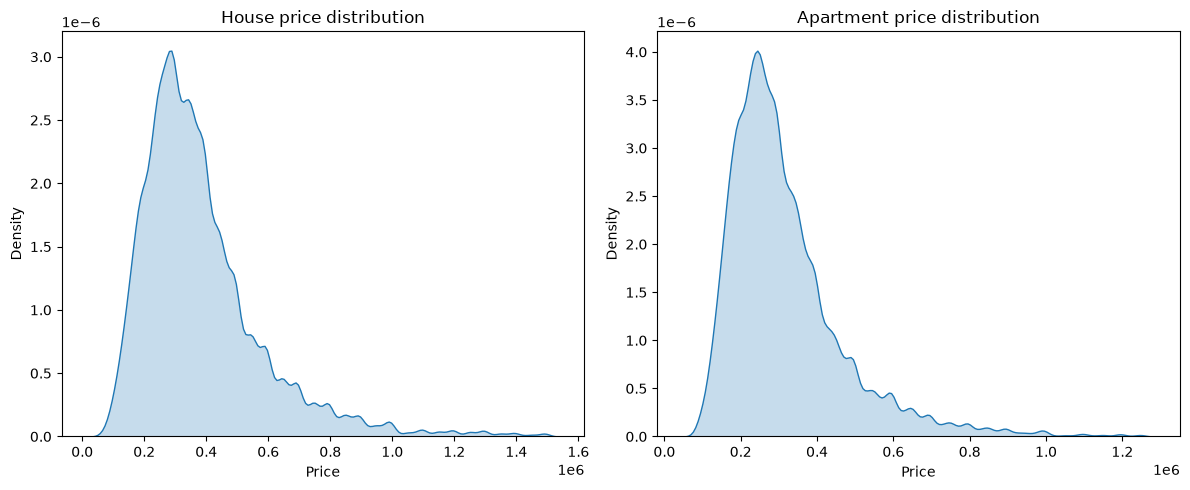

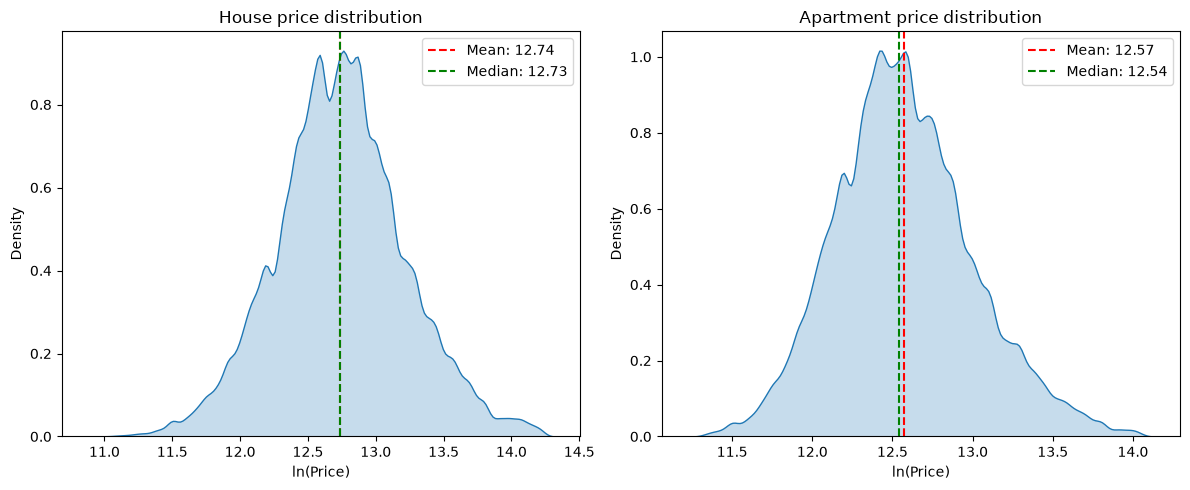

In [7]:
# ---------------------------------------------------------------------------
# 3. Plot price distribution
# ---------------------------------------------------------------------------

# Combine year and month into a single column
data_realo['firstListing year_month'] = data_realo['firstListing'].dt.to_period('M')
data_realo['lastListing year_month'] = data_realo['lastListing'].dt.to_period('M')

# Let's see what the distribution of 'Price' looks like for both apartments and houses
# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot KDE for 'HOUSE' on the left subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'HOUSE'], x='price', ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('Price')
ax1.set_ylabel('Density')

# Plot KDE for 'APARTMENT' on the right subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'APARTMENT'], x='price', ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('Price')
ax2.set_ylabel('Density')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# This data seems to be log-normally distributed. Let's do a log-transform and 
# plot again

data_realo["ln(price)"] = np.log(data_realo["price"]) 
data_realo["ln(initialPrice)"] = np.log(data_realo["initialPrice"]) 

# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: HOUSE 
house_data = data_realo[data_realo['housingType'] == 'HOUSE']['ln(price)']
sns.kdeplot(data=house_data, ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('ln(Price)')
ax1.set_ylabel('Density')

# Calculate mean and median for HOUSE
mean_house = house_data.mean()
median_house = house_data.median()

# Add vertical lines for mean and median
ax1.axvline(mean_house, color='red', linestyle='--', label=f'Mean: {mean_house:.2f}')
ax1.axvline(median_house, color='green', linestyle='--', label=f'Median: {median_house:.2f}')
ax1.legend()

# Right subplot: APARTMENT 
apartment_data = data_realo[data_realo['housingType'] == 'APARTMENT']['ln(price)']
sns.kdeplot(data=apartment_data, ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('ln(Price)')
ax2.set_ylabel('Density')

# Calculate mean and median for APARTMENT
mean_apartment = apartment_data.mean()
median_apartment = apartment_data.median()

# Add vertical lines for mean and median
ax2.axvline(mean_apartment, color='red', linestyle='--', label=f'Mean: {mean_apartment:.2f}')
ax2.axvline(median_apartment, color='green', linestyle='--', label=f'Median: {median_apartment:.2f}')
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [8]:
# ---------------------------------------------------------------------------
# 5. Plot evolution house prices, CPI, and gross income
# ---------------------------------------------------------------------------

data_CPI = pd.read_excel("CPI index.xlsx", sheet_name="CPI")
gross_income_data = pd.read_excel("evolution.xlsx",
                                  sheet_name= "NUTS3")

In [9]:
data_prices = data_realo.copy()
data_prices = data_prices[data_prices["estimatedArea"]!= np.nan]
data_prices["price/m2"] = data_prices["price"] / data_prices["estimatedArea"]

In [10]:
import numpy as np
import pandas as pd

base_year = 2026

df = data_realo
df['pm2'] = df['price'] / df['habitableArea']
df['year_last'] = pd.to_datetime(df['lastListing'], errors='coerce').dt.year
df['year_first'] = pd.to_datetime(df['firstListing'], errors='coerce').dt.year

# mean price/m2 per housing type per year
level = df.groupby(['housingType', 'year_last'])['pm2'].mean().unstack('year_last')

# factor = 2026 level / level of that year
factor = level.div(level[base_year], axis=0).rdiv(1)   # = level[base_year] / level

# look up the factor for every listing
def get_factor(year_col):
    idx = pd.MultiIndex.from_arrays([df['housingType'], df[year_col]])
    return pd.Series(factor.stack().reindex(idx).to_numpy(), index=df.index)

f_last = get_factor('year_last')
f_first = get_factor('year_first')

df['inflation_factor'] = f_last
df['price_adj'] = df['price'] * f_last
df['initialPrice_adj'] = df['initialPrice'] * f_first
df['ln(price_adj)'] = df['ln(price)'] + np.log(f_last)
df['ln(initialPrice_adj)'] = df['ln(initialPrice)'] + np.log(f_first)
df['price/m2hab_adj'] = df['price_adj'] / df['habitableArea']

data_prices_adj = df

print(level.round(0))
print(f_last.isna().sum(), "rows without a factor")

year_last    2015.0  2016.0  2017.0  2018.0  2019.0  2020.0  2021.0  2022.0  \
housingType                                                                   
APARTMENT    2546.0  2683.0  2808.0  2905.0  3077.0  3215.0  3290.0  3370.0   
HOUSE        1695.0  1765.0  1776.0  1855.0  1898.0  2038.0  2115.0  2208.0   

year_last    2023.0  2024.0  2025.0  2026.0  
housingType                                  
APARTMENT    3437.0  3531.0  3566.0  3610.0  
HOUSE        2272.0  2305.0  2333.0  2380.0  
12672 rows without a factor


In [11]:
# --- Function: plot the evolution of house prices, CPI and gross income -----

def plot_index_evolution(data_prices=data_realo, data_CPI=data_CPI,
                         data_income=gross_income_data,
                         start_date="01/2015", end_date="08/2026", Lags=0):
    """
    Plot, per admin2 region, the indexed evolution (start_date = 100) of the
    median listing price of houses and apartments, the CPI and gross income.

    Parameters
    ----------
    data_prices : DataFrame with 'admin2', 'housingType',
                  'lastListing year_month' and 'price'.
    data_CPI    : DataFrame with 'Date' ("MM/YYYY" or datetime) and 'CPI index'.
    data_income : DataFrame with 'Abbreviated name' and one column per year.
    start_date  : base month and first month shown, "MM/YYYY".
    end_date    : last month shown, "MM/YYYY".
    Lags        : number of lags used for the price series ONLY. The price
                  in month t is the median of all listings in months
                  t-Lags, ..., t (pooled). Lags = 0 -> monthly median;
                  Lags = 11 -> 12 months of data (t-11 up to t).

    Raises
    ------
    ValueError if the price data of a region/housing type does not reach back
    to start_date - Lags, or if the CPI or gross income data do not contain
    the base period.
    """

    # --- Check and convert the arguments ------------------------------------
    if not isinstance(Lags, int) or Lags < 0:
        raise ValueError("Lags must be a non-negative integer.")
    start = pd.Period(pd.to_datetime(start_date, format="%m/%Y"), freq="M")
    end = pd.Period(pd.to_datetime(end_date, format="%m/%Y"), freq="M")
    if start > end:
        raise ValueError("start_date must be before end_date.")
    first_needed = start - Lags   # first month needed for the lagged series
    months = pd.period_range(start, end, freq="M")

    # Work on copies so that the original dataframes are not modified
    data_prices = data_prices.copy()
    data_CPI = data_CPI.copy()
    data_income = data_income.copy()

    # --- CPI: convert 'Date' ("MM/YYYY") to datetime --------------------------
    if not pd.api.types.is_datetime64_any_dtype(data_CPI["Date"]):
        data_CPI["Date"] = pd.to_datetime(data_CPI["Date"].astype(str),
                                          format="%m/%Y")
    cpi = data_CPI.set_index(data_CPI["Date"].dt.to_period("M"))["CPI index"]
    if start not in cpi.index:
        raise ValueError(f"The CPI data has no observation for {start_date} "
                         f"(it covers {cpi.index.min()} to {cpi.index.max()}).")
    cpi_index = cpi / cpi[start] * 100
    cpi_index = cpi_index[(cpi_index.index >= start) & (cpi_index.index <= end)]

    # --- Gross income: keep the relevant regions -----------------------------
    income_regions = ["Brussels Hoofdstedelijk Gewest", "Aalst", "Dendermonde",
                      "Eeklo", "Gent", "Oudenaarde", "Sint-Niklaas"]
    data_income = data_income[data_income["Abbreviated name"].isin(income_regions)]
    income_year_cols = [c for c in data_income.columns if str(c).isdigit()]
    income = data_income.set_index("Abbreviated name")[income_year_cols]
    income.columns = income.columns.astype(int)
    if start.year not in income.columns:
        raise ValueError(f"The gross income data has no observation for "
                         f"{start.year} (it covers {min(income.columns)} to "
                         f"{max(income.columns)}).")
    income_index = income.div(income[start.year], axis=0) * 100
    income_index = income_index.loc[:, (income_index.columns >= start.year)
                                       & (income_index.columns <= end.year)]

    # Link the 'admin2' names in the Realo data to the names in the income data
    region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
                  "Aalst": "Aalst", "Dendermonde": "Dendermonde",
                  "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
                  "Sint-Niklaas": "Sint-Niklaas"}

    # --- Prices: (lagged) median price index per region and housing type ----
    data_prices = data_prices.dropna(subset=["admin2", "housingType",
                                             "lastListing year_month", "price"])

    def lagged_median_index(region, housing_type):
        """Pooled median over months t-Lags ... t, indexed to start = 100."""
        sub = data_prices[(data_prices["admin2"] == region)
                          & (data_prices["housingType"] == housing_type)]
        listing_month = sub["lastListing year_month"]
        price = sub["price"].astype(float)

        # Error if the data does not reach back far enough
        if sub.empty or listing_month.min() > first_needed:
            first_available = "none" if sub.empty else listing_month.min()
            raise ValueError(
                f"Too few datapoints for {housing_type} in {region}: with "
                f"Lags = {Lags}, data from {first_needed} onwards is needed, "
                f"but the first observation is {first_available}.")

        median = pd.Series(
            [price[(listing_month >= t - Lags) & (listing_month <= t)].median()
             for t in months],
            index=months)

        if pd.isna(median[start]):
            raise ValueError(
                f"No {housing_type} listings for {region} in the window "
                f"{first_needed} to {start}; the base value cannot be computed.")
        return median / median[start] * 100

    # --- Plot: one panel per region ------------------------------------------
    window_label = "" if Lags == 0 else f" ({Lags + 1}-month window)"

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, (region, income_name) in zip(axes, region_map.items()):

        # Median price index for houses and apartments
        for housing_type, label, color in [("HOUSE", "Median price houses", "tab:blue"),
                                           ("APARTMENT", "Median price apartments", "tab:orange")]:
            price_index = lagged_median_index(region, housing_type)
            ax.plot(price_index.index.to_timestamp(), price_index.values,
                    label=label + window_label, color=color, linewidth=1)

        # CPI index
        ax.plot(cpi_index.index.to_timestamp(), cpi_index.values,
                label="CPI", color="black", linewidth=1.5)

        # Gross income index, plotted in January of each year
        region_income = income_index.loc[income_name]
        income_dates = pd.to_datetime([f"{year}-01-01" for year in region_income.index])
        ax.plot(income_dates, region_income.values, label="Gross income",
                color="tab:green", marker="o", markersize=3, linewidth=1.5)

        ax.axhline(100, color="grey", linestyle=":", linewidth=1)
        ax.set_title(region)
        ax.tick_params(axis="x", rotation=45)

    # Show only the period start_date - end_date
    axes[0].set_xlim(start.to_timestamp(), end.to_timestamp(how="end"))

    # Hide the axes of the empty eighth panel (it is used for the legend below)
    for ax in axes[len(region_map):]:
        ax.axis("off")

    for ax in axes[::4]:
        ax.set_ylabel(f"Index ({start_date} = 100)")

    # One shared legend (taken from the first panel), placed inside the empty
    # eighth panel so that it cannot overlap with any of the region panels
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    fig.suptitle(f"Evolution of median listing prices, CPI and gross income "
                 f"(index, {start_date} = 100; gross income: {start.year} = 100; "
                 f"Lags = {Lags})",
                 fontsize=14)
    plt.tight_layout()
    plt.show()

    return fig


# Plot with the default settings (monthly medians, 01/2015 - 08/2026)
#plot_index_evolution(end_date="10/2026")

# Plot for period 01/2017-08/2026 with lags = 11s

In [12]:
# ---------------------------------------------------------------------------
# 6. Yearly gaps: house prices vs CPI, and house prices vs gross income
# ---------------------------------------------------------------------------
# Run this after the cells above: it uses data_realo, data_CPI and
# gross_income_data.
#
# Definitions (per year, in percentage points):
#   gap vs CPI    = growth of the median listing price - CPI inflation
#   gap vs income = growth of the median listing price - growth of gross income
# Growth in year t is the change compared with year t-1.
# A gap of +3 means prices grew 3 percentage points faster than CPI (or than
# gross income) that year; -3 means they grew 3 points slower.
#
# Price = median listing price of the listings whose 'lastListing' falls in
# that year. CPI = average of the monthly CPI values in that year.

region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
              "Aalst": "Aalst", "Dendermonde": "Dendermonde",
              "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
              "Sint-Niklaas": "Sint-Niklaas"}
housing_types = ["HOUSE", "APARTMENT"]


def compute_yearly_gaps(data_prices=data_realo, data_CPI=data_CPI,
                        data_income=gross_income_data,
                        first_year=2015, last_year=2025):
    """
    Compute, per region and housing type, the yearly gap (in percentage
    points) between house price growth and (a) CPI inflation, (b) gross
    income growth.

    Parameters
    ----------
    first_year : base year; the first gap is reported for first_year + 1.
    last_year  : last year included. Use a full year (the data for the most
                 recent year is incomplete).

    Returns
    -------
    gaps_cpi, gaps_income : dicts {housing type: DataFrame}, each DataFrame
        with the years as rows and the regions as columns.
    """
    years = list(range(first_year, last_year + 1))

    # --- CPI: yearly average, then yearly inflation in % --------------------
    cpi = data_CPI.copy()
    if not pd.api.types.is_datetime64_any_dtype(cpi["Date"]):
        cpi["Date"] = pd.to_datetime(cpi["Date"].astype(str), format="%m/%Y")
    cpi_year = cpi.groupby(cpi["Date"].dt.year)["CPI index"].mean()
    missing = [y for y in years if y not in cpi_year.index]
    if missing:
        raise ValueError(f"The CPI data does not cover year(s) {missing}.")
    cpi_year = cpi_year.loc[years].astype(float)
    cpi_growth = (cpi_year / cpi_year.shift(1) - 1) * 100

    # --- Gross income: yearly growth in % per region ------------------------
    inc = data_income[data_income["Abbreviated name"].isin(region_map.values())]
    year_cols = [c for c in inc.columns if str(c).isdigit()]
    inc = inc.set_index("Abbreviated name")[year_cols]
    inc.columns = inc.columns.astype(int)
    missing = [y for y in years if y not in inc.columns]
    if missing:
        raise ValueError(f"The gross income data does not cover year(s) "
                         f"{missing} (it covers {min(inc.columns)} to "
                         f"{max(inc.columns)}). Lower last_year.")
    inc = inc[years].astype(float)
    inc_growth = (inc / inc.shift(1, axis=1) - 1) * 100

    # --- Prices: yearly median listing price per region and housing type ----
    p = data_prices.dropna(subset=["admin2", "housingType",
                                   "lastListing", "price"]).copy()
    p["admin2"] = p["admin2"].astype(str)
    p["housingType"] = p["housingType"].astype(str)
    p["price"] = p["price"].astype(float)
    p["year"] = p["lastListing"].dt.year
    median = (p.groupby(["admin2", "housingType", "year"])["price"].median()
                .unstack("year").reindex(columns=years))

    # --- Gaps ----------------------------------------------------------------
    gaps_cpi = {}
    gaps_income = {}
    for housing_type in housing_types:
        vs_cpi = {}
        vs_income = {}
        for region, income_name in region_map.items():
            if (region, housing_type) not in median.index:
                raise ValueError(f"No {housing_type} listings for {region}.")
            price = median.loc[(region, housing_type)]
            if price.isna().any():
                no_data = [y for y in years if pd.isna(price[y])]
                raise ValueError(f"No {housing_type} listings for {region} "
                                 f"in year(s) {no_data}.")
            price_growth = (price / price.shift(1) - 1) * 100
            vs_cpi[region] = price_growth - cpi_growth
            vs_income[region] = price_growth - inc_growth.loc[income_name]
        gaps_cpi[housing_type] = pd.DataFrame(vs_cpi).iloc[1:]
        gaps_income[housing_type] = pd.DataFrame(vs_income).iloc[1:]
        gaps_cpi[housing_type].index.name = "Year"
        gaps_income[housing_type].index.name = "Year"

    return gaps_cpi, gaps_income


def plot_yearly_gaps(gaps, title, ylabel):
    """One panel per region: yearly gap for houses and apartments (bars)."""
    years = list(gaps["HOUSE"].index)
    x = np.arange(len(years))
    width = 0.4

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, region in zip(axes, region_map):
        ax.bar(x - width / 2, gaps["HOUSE"][region].values, width,
               label="Houses", color="tab:blue")
        ax.bar(x + width / 2, gaps["APARTMENT"][region].values, width,
               label="Apartments", color="tab:orange")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(region)
        ax.set_xticks(x)
        ax.set_xticklabels(years, rotation=45)

    # Hide the empty eighth panel and use it for the legend
    for ax in axes[len(region_map):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    for ax in axes[::4]:
        ax.set_ylabel(ylabel)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig


def print_gap_tables(gaps, title):
    """Print one table per housing type: rows = years, columns = regions."""
    for housing_type in housing_types:
        table = gaps[housing_type]
        table = pd.concat([table, table.mean().to_frame("Average").T])
        print("\n" + "=" * 70)
        print(f"{title} - {housing_type} (percentage points)")
        print("=" * 70)
        print(table.to_string(float_format=lambda v: f"{v:+.1f}"))


# --- Run ---------------------------------------------------------------------
# Years 2016-2025 (2015 is the base year; 2026 is left out because it is
# incomplete). Change first_year / last_year if you want another period.
#gaps_cpi, gaps_income = compute_yearly_gaps(first_year=2015, last_year=2022)

#plot_yearly_gaps(gaps_cpi,
                # "Median listing price growth minus CPI inflation, per year",
                 #"Percentage points")
#plot_yearly_gaps(gaps_income,
                 #"Median listing price growth minus gross income growth, "
                 #"per year",
                 #"Percentage points")

#print_gap_tables(gaps_cpi, "PRICE GROWTH MINUS CPI INFLATION")
#print_gap_tables(gaps_income, "PRICE GROWTH MINUS GROSS INCOME GROWTH")

In [13]:
# ---------------------------------------------------------------------------
# 6. Yearly gaps: house prices vs CPI, and house prices vs gross income
# ---------------------------------------------------------------------------
# Run this after the cells above: it uses data_realo, data_CPI and
# gross_income_data.
#
# Definitions (per year, in percentage points):
#   gap vs CPI    = growth of the median listing price - CPI inflation
#   gap vs income = growth of the median listing price - growth of gross income
# Growth in year t is the change compared with year t-1.
# A gap of +3 means prices grew 3 percentage points faster than CPI (or than
# gross income) that year; -3 means they grew 3 points slower.
#
# Price = median listing price of the listings whose 'lastListing' falls in
# that year. CPI = average of the monthly CPI values in that year.

region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
              "Aalst": "Aalst", "Dendermonde": "Dendermonde",
              "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
              "Sint-Niklaas": "Sint-Niklaas"}
housing_types = ["HOUSE", "APARTMENT"]


def compute_yearly_gaps(data_prices=data_realo, data_CPI=data_CPI,
                        first_year=2015, last_year=2025):
    """
    Compute, per region and housing type, the yearly gap (in percentage
    points) between house price growth and (a) CPI inflation, (b) gross
    income growth.

    Parameters
    ----------
    first_year : base year; the first gap is reported for first_year + 1.
    last_year  : last year included. Use a full year (the data for the most
                 recent year is incomplete).

    Returns
    -------
    gaps_cpi, gaps_income : dicts {housing type: DataFrame}, each DataFrame
        with the years as rows and the regions as columns.
    """
    data_prices = data_prices[data_prices["estimatedArea"]!= np.nan]
    data_prices["price/m2"] = data_prices["price"] / data_prices["estimatedArea"]
    
    

    years = list(range(first_year, last_year + 1))

    # --- CPI: yearly average, then yearly inflation in % --------------------
    cpi = data_CPI.copy()
    if not pd.api.types.is_datetime64_any_dtype(cpi["Date"]):
        cpi["Date"] = pd.to_datetime(cpi["Date"].astype(str), format="%m/%Y")
    cpi_year = cpi.groupby(cpi["Date"].dt.year)["CPI index"].mean()
    missing = [y for y in years if y not in cpi_year.index]
    if missing:
        raise ValueError(f"The CPI data does not cover year(s) {missing}.")
    cpi_year = cpi_year.loc[years].astype(float)
    cpi_growth = (cpi_year / cpi_year.shift(1) - 1) * 100

   

    # --- Prices: yearly median listing price per region and housing type ----
    p = data_prices.dropna(subset=["admin2", "housingType",
                                   "lastListing", "price/m2"]).copy()
    p["admin2"] = p["admin2"].astype(str)
    p["housingType"] = p["housingType"].astype(str)
    p["price/m2"] = p["price/m2"].astype(float)
    p["year"] = p["lastListing"].dt.year
    median = (p.groupby(["admin2", "housingType", "year"])["price/m2"].median()
                .unstack("year").reindex(columns=years))

    # --- Gaps ----------------------------------------------------------------
    gaps_cpi = {}
    
    for housing_type in housing_types:
        vs_cpi = {}
        for region, income_name in region_map.items():
            if (region, housing_type) not in median.index:
                raise ValueError(f"No {housing_type} listings for {region}.")
            price = median.loc[(region, housing_type)]
            if price.isna().any():
                no_data = [y for y in years if pd.isna(price[y])]
                raise ValueError(f"No {housing_type} listings for {region} "
                                 f"in year(s) {no_data}.")
            price_growth = (price / price.shift(1) - 1) * 100
            vs_cpi[region] = price_growth - cpi_growth
        gaps_cpi[housing_type] = pd.DataFrame(vs_cpi).iloc[1:]
        gaps_cpi[housing_type].index.name = "Year"

    return gaps_cpi


def plot_yearly_gaps(gaps, title, ylabel):
    """One panel per region: yearly gap for houses and apartments (bars)."""
    years = list(gaps["HOUSE"].index)
    x = np.arange(len(years))
    width = 0.4

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, region in zip(axes, region_map):
        ax.bar(x - width / 2, gaps["HOUSE"][region].values, width,
               label="Houses", color="tab:blue")
        ax.bar(x + width / 2, gaps["APARTMENT"][region].values, width,
               label="Apartments", color="tab:orange")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(region)
        ax.set_xticks(x)
        ax.set_xticklabels(years, rotation=45)

    # Hide the empty eighth panel and use it for the legend
    for ax in axes[len(region_map):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    for ax in axes[::4]:
        ax.set_ylabel(ylabel)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig


def print_gap_tables(gaps, title):
    """Print one table per housing type: rows = years, columns = regions."""
    for housing_type in housing_types:
        table = gaps[housing_type]
        table = pd.concat([table, table.mean().to_frame("Average").T])
        print("\n" + "=" * 70)
        print(f"{title} - {housing_type} (percentage points)")
        print("=" * 70)
        print(table.to_string(float_format=lambda v: f"{v:+.1f}"))


# --- Run ---------------------------------------------------------------------
# Years 2016-2025 (2015 is the base year; 2026 is left out because it is
# incomplete). Change first_year / last_year if you want another period.
#gaps_cpi = compute_yearly_gaps(data_prices = data_realo.copy(), first_year=2015, last_year=2026)
#plot_yearly_gaps(gaps_cpi,
 #                "Median listing price growth minus CPI inflation, per year",
  #               "Percentage points")


#print_gap_tables(gaps_cpi, "PRICE GROWTH MINUS CPI INFLATION")


In [14]:
import matplotlib.pyplot as plt

#Algemene plotfunctie met optionele jaarlijkse percentiel-buckets
def plot_data(
    data,
    x,
    y,
    split_by=None,
    agg="mean",
    freq=None,
    where=None,
    kind="line",
    bins=None,
    labels=None,
    title=None,
    xlabel=None,
    ylabel=None,
    figsize=(11, 6),
    bucket_by_year=False,
    bucket_col="price/m2",
    bucket_labels=None,
    bucket_percentiles=None,
):
    """
    General-purpose plotting function with optional yearly percentile buckets.

    Parameters
    ----------
    data : DataFrame
        Input dataset.
    x, y : str
        Columns for the axes.
        Special y values: 'price/m2', 'growth'.
    split_by : str, optional
        Column used to create separate series.
        Use 'yearly_bucket' to plot yearly percentile buckets.
    agg : str or None
        'mean', 'median', 'sum', 'count', or None.
    freq : str, optional
        Time frequency, e.g. 'M', 'Q', 'Y'.
    where : dict, optional
        Filters, e.g. {'housingType': 'HOUSE'}.
    kind : str
        'line', 'scatter', or 'bar'.
    bucket_by_year : bool
        If True, classify observations into percentile buckets
        calculated separately for each year.
    bucket_col : str
        Column used to determine percentile rank.
    bucket_labels : list, optional
        Names for the percentile buckets.
    bucket_percentiles : list, optional
        Upper percentile limits, e.g. [0.75, 0.90, 0.99, 1.0].

    Returns
    -------
    fig : matplotlib Figure
    """

    df = data.copy()

    # Apply filters
    if where:
        for col, value in where.items():
            if isinstance(value, (list, tuple, set)):
                df = df[df[col].isin(value)]
            else:
                df = df[df[col] == value]

    # Calculate price per square metre if needed
    if (
        x== "price/m2"
        or
        y == "price/m2"
        or bucket_col == "price/m2"
        or split_by == "price/m2"
    ):
        if "price/m2" not in df.columns:
            price = pd.to_numeric(df["price"], errors="coerce")
            area = pd.to_numeric(
                df["estimatedArea"], errors="coerce"
            )
            df["price/m2"] = (price / area).where(area > 0)

    # Convert the x column to dates if appropriate
    date_axis = (
        pd.api.types.is_datetime64_any_dtype(df[x])
        or any(word in x.lower() for word in ["date", "time"])
    )

    if date_axis:
        df[x] = pd.to_datetime(df[x], errors="coerce")

    # Determine the year used for yearly buckets
    if bucket_by_year:
        if date_axis:
            df["_bucket_year"] = df[x].dt.year
        elif x.lower() == "year":
            df["_bucket_year"] = pd.to_numeric(
                df[x], errors="coerce"
            )
        else:
            raise ValueError(
                "Yearly buckets require a date x column "
                "or x='year'."
            )

        # Default percentile boundaries
        if bucket_percentiles is None:
            bucket_percentiles = [0.75, 0.90, 0.99, 1.0]

        if bucket_labels is None:
            bucket_labels = [
                "Bottom 75%",
                "75–90%",
                "90–99%",
                "Top 1%",
            ]

        if len(bucket_labels) != len(bucket_percentiles):
            raise ValueError(
                "bucket_labels and bucket_percentiles "
                "must have the same length."
            )

        if (
            any(
                not 0 < p <= 1
                for p in bucket_percentiles
            )
            or sorted(bucket_percentiles) != bucket_percentiles
            or bucket_percentiles[-1] != 1.0
        ):
            raise ValueError(
                "Percentile boundaries must be increasing, "
                "between 0 and 1, and end at 1.0."
            )

        # Rank each observation within its year
        df["_bucket_value"] = pd.to_numeric(
            df[bucket_col], errors="coerce"
        )

        df = df.dropna(
            subset=["_bucket_year", "_bucket_value"]
        )

        df["_percentile"] = df.groupby(
            "_bucket_year"
        )["_bucket_value"].rank(
            pct=True, method="average"
        )

        # Convert percentile ranks into named buckets
        boundaries = [0] + bucket_percentiles

        df["yearly_bucket"] = pd.cut(
            df["_percentile"],
            bins=boundaries,
            labels=bucket_labels,
            include_lowest=True,
            right=True,
        )

        if split_by == "yearly_bucket":
            split_by = "yearly_bucket"

    # Calculate percentage growth if requested
    if y == "growth":
        if "price" not in df.columns:
            raise ValueError(
                "y='growth' requires a 'price' column."
            )

        df[y] = pd.to_numeric(df["price"], errors="coerce")

    elif y not in df.columns:
        raise ValueError(f"Column '{y}' not found.")

    df[y] = pd.to_numeric(df[y], errors="coerce")
    df = df.dropna(subset=[x, y])

    # Sort before any growth calculation
    df = df.sort_values(x)

    # Growth is calculated on the aggregated series below
    if y == "growth":
        y_source = "price"
    else:
        y_source = y

    # Prepare data for aggregation
    if freq is not None:
        df = df.set_index(x).sort_index()

        if split_by:
            grouped = df.groupby(
                split_by, observed=True
            )[y_source].resample(freq)
        else:
            grouped = df[y_source].resample(freq)

        if agg == "median":
            result = grouped.median()
        elif agg == "sum":
            result = grouped.sum()
        elif agg == "count":
            result = grouped.count()
        elif agg == "mean":
            result = grouped.mean()
        elif agg is None:
            raise ValueError(
                "Choose an aggregation when using freq."
            )
        else:
            raise ValueError(
                "agg must be mean, median, sum, count, or None."
            )

        if split_by:
            result = result.unstack(0)
        else:
            result = result.to_frame(y_source)

        # Calculate growth from the aggregated values
        if y == "growth":
            result = result.pct_change() * 100
            result.columns.name = None

        grouped_data = result

    elif agg is not None:
        group_cols = [x] + ([split_by] if split_by else [])
        grouped = df.groupby(
            group_cols, observed=True
        )[y_source]

        if agg == "median":
            result = grouped.median()
        elif agg == "sum":
            result = grouped.sum()
        elif agg == "count":
            result = grouped.count()
        elif agg == "mean":
            result = grouped.mean()
        else:
            raise ValueError(
                "agg must be mean, median, sum, count, or None."
            )

        if split_by:
            result = result.unstack(split_by)

        if y == "growth":
            if split_by:
                result = result.pct_change() * 100
            else:
                result = result.pct_change() * 100

        grouped_data = result

    else:
        # Plot individual observations without aggregation
        grouped_data = None

    # Plot
    if grouped_data is not None:
        if kind == "bar":
            ax = grouped_data.plot(
                kind="bar", figsize=figsize, rot=45
            )
        elif kind == "scatter":
            fig, ax = plt.subplots(figsize=figsize)
            if isinstance(grouped_data, pd.DataFrame):
                for col in grouped_data.columns:
                    ax.scatter(
                        grouped_data.index,
                        grouped_data[col],
                        label=str(col),
                        alpha=0.7,
                    )
                ax.legend()
            else:
                ax.scatter(
                    grouped_data.index,
                    grouped_data,
                    alpha=0.7,
                )
        else:
            ax = grouped_data.plot(
                kind="line",
                figsize=figsize,
                marker="o",
            )

        fig = ax.figure

    else:
        fig, ax = plt.subplots(figsize=figsize)

        if split_by:
            for name, group in df.groupby(
                split_by, observed=True
            ):
                ax.scatter(
                    group[x], group[y],
                    label=str(name), alpha=0.6
                ) if kind == "scatter" else ax.plot(
                    group[x], group[y],
                    label=str(name) 
                )

            ax.legend()
        elif kind == "scatter":
            ax.scatter(df[x], df[y], alpha=0.6)
        else:
            ax.plot(df[x], df[y])

    ax.set_title(title or f"{y} vs {x}")
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(
        ylabel or (
            "Growth (%)" if y == "growth" else y
        )
    )
    ax.legend(title=str(split_by[0])+ ' ' + str(bucket_col) or None)
    ax.grid(True, alpha=0.3)
    

    plt.tight_layout()
    plt.show()

    return fig


In [15]:
import pandas as pd


def _extract_year(s):
    """Robustly get a year from datetime, Period, 'YYYY-MM' strings, 202305 ints or plain years."""
    if pd.api.types.is_datetime64_any_dtype(s) or isinstance(s.dtype, pd.PeriodDtype):
        return pd.to_numeric(s.dt.year, errors="coerce")
    if pd.api.types.is_numeric_dtype(s):
        v = pd.to_numeric(s, errors="coerce")
        return v.where(v < 100000, v // 100)      # 202305 -> 2023, 2023 -> 2023
    # strings / objects: take the first 4-digit number ('2023-05', '2023/05/01', 'Q1 2023' ...)
    return pd.to_numeric(s.astype(str).str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")


def summarize_buckets(
    data,
    x="date",                  # date / year / year_month column
    value="mscore",            # the metric you want to average / analyse
    bucket_col="price/m2",     # column that defines the percentile buckets
    bucket_percentiles=None,   # upper limits, e.g. [0.75, 0.90, 0.99, 1.0]
    bucket_labels=None,
    where=None,                # filters, e.g. {"housingType": "HOUSE"}
    only_buckets=None,         # e.g. ["Top 1%"] to keep just some buckets
    agg="mean",                # 'mean', 'median', 'sum'
    show=True,                 # print the tables
    decimals=3,
    plot=False,                # line chart of the mean value per bucket per year
):
    """
    Split observations into percentile buckets (calculated separately per year)
    and summarise `value` per year and bucket.

    Returns a dict of DataFrames: counts, values, yoy_pct, index, bucket_range, long.
    """
    df = data.copy()
    print(f"[start] {len(df)} rows")

    # --- filters -----------------------------------------------------------
    if where:
        for col, val in where.items():
            if col not in df.columns:
                raise KeyError(f"Filter column '{col}' not found. Columns: {list(df.columns)}")
            if isinstance(val, (list, tuple, set)):
                df = df[df[col].isin(val)]
            else:
                df = df[df[col] == val]
        print(f"[after where={where}] {len(df)} rows")
        if df.empty:
            raise ValueError(f"Filter {where} matches nothing. Check the exact values, e.g. "
                             f"data[{list(where)[0]!r}].unique()")

    for col in (x, value):
        if col not in df.columns:
            raise KeyError(f"Column '{col}' not found. Columns: {list(df.columns)}")

    # --- price per m2 if needed -------------------------------------------
    if bucket_col == "price/m2" and "price/m2" not in df.columns:
        price = pd.to_numeric(df["price"], errors="coerce")
        area = pd.to_numeric(df["estimatedArea"], errors="coerce")
        df["price/m2"] = (price / area).where(area > 0)
    if bucket_col not in df.columns:
        raise KeyError(f"bucket_col '{bucket_col}' not found.")

    # --- year --------------------------------------------------------------
    df["_year"] = _extract_year(df[x])
    df["_bval"] = pd.to_numeric(df[bucket_col], errors="coerce")
    df["_val"] = pd.to_numeric(df[value], errors="coerce")

    print(f"[valid] year: {df['_year'].notna().sum()}  |  {bucket_col}: {df['_bval'].notna().sum()}"
          f"  |  {value}: {df['_val'].notna().sum()}  (of {len(df)})")

    df = df.dropna(subset=["_year", "_bval", "_val"])
    if df.empty:
        raise ValueError(
            "No rows left. See the [valid] counts above: the column with 0 (or very few) valid "
            f"values is the problem. Sample of '{x}': {data[x].head(3).tolist()}, "
            f"'{value}': {data[value].head(3).tolist()}"
        )
    df["_year"] = df["_year"].astype(int)
    print(f"[final] {len(df)} rows, years {df['_year'].min()}-{df['_year'].max()}")

    # --- defaults ----------------------------------------------------------
    if bucket_percentiles is None:
        bucket_percentiles = [0.75, 0.90, 0.99, 1.0]
    if bucket_labels is None:
        bucket_labels = ["Bottom 75%", "75-90%", "90-99%", "Top 1%"]
    if len(bucket_labels) != len(bucket_percentiles):
        raise ValueError("bucket_labels and bucket_percentiles must have the same length.")
    if sorted(bucket_percentiles) != list(bucket_percentiles) or bucket_percentiles[-1] != 1.0:
        raise ValueError("bucket_percentiles must be increasing and end at 1.0.")

    # --- percentile rank within each year -> bucket ------------------------
    df["_pct"] = df.groupby("_year")["_bval"].rank(pct=True, method="average")
    df["bucket"] = pd.cut(
        df["_pct"],
        bins=[0] + list(bucket_percentiles),
        labels=bucket_labels,
        include_lowest=True,
        right=True,
    )

    if only_buckets:
        df = df[df["bucket"].isin(only_buckets)]

    # --- aggregate ---------------------------------------------------------
    g = df.groupby(["_year", "bucket"], observed=True)
    long = g["_val"].agg(["count", "mean", "median", "std", "min", "max"])
    long["agg_value"] = g["_val"].agg(agg)
    long[f"{bucket_col}_min"] = g["_bval"].min()
    long[f"{bucket_col}_max"] = g["_bval"].max()
    long[f"{bucket_col}_mean"] = g["_bval"].mean()
    long.index.names = ["year", "bucket"]

    counts = long["count"].unstack("bucket")
    values = long["agg_value"].unstack("bucket")
    yoy = values.pct_change(fill_method=None) * 100
    first = values.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else float("nan"))
    last = values.apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else float("nan"))
    index = values.div(first) * 100
    bucket_range = long[[f"{bucket_col}_min", f"{bucket_col}_max"]].unstack("bucket")
    bucket_means = long[f"{bucket_col}_mean"].unstack("bucket")

    # evolution table: the value per year per bucket + change columns
    evolution = values.copy()
    evolution.loc["Δ first→last"] = values.apply(
        lambda s: s.dropna().iloc[-1] - s.dropna().iloc[0] if s.notna().any() else float("nan"))
    evolution.loc["Δ first→last (%)"] = (last / first - 1) * 100

    # --- print -------------------------------------------------------------
    if show:
        pd.set_option("display.width", 200)
        pd.set_option("display.max_columns", None)
        print(f"\n=== {agg} of '{value}' per year, buckets by '{bucket_col}' "
              f"(percentiles calculated per year) ===")
        print(f"\nObservations per bucket:\n{counts.to_string()}")
        print(f"\n{agg.capitalize()} {value} per bucket per year (evolution, rows = years):\n"
              f"{evolution.round(decimals).to_string()}")
        print(f"\nYear-over-year change of the {agg} {value} (%):\n{yoy.round(1).to_string()}")
        print(f"\nAverage {bucket_col} per bucket per year:\n{bucket_means.round(1).to_string()}\n")

    if plot:
        import matplotlib.pyplot as plt
        ax = values.plot(marker="o", figsize=(10, 5))
        ax.set_title(f"{agg.capitalize()} {value} per year, by {bucket_col} bucket")
        ax.set_xlabel("year")
        ax.set_ylabel(f"{agg} {value}")
        ax.grid(True, alpha=0.3)
        ax.legend(title=f"{bucket_col} bucket")
        plt.tight_layout()
        plt.show()

    return {
        "counts": counts,
        "values": values,
        "evolution": evolution,
        "bucket_means": bucket_means,
        "yoy_pct": yoy,
        "index": index,
        "bucket_range": bucket_range,
        "long": long.reset_index(),
    }

In [17]:
res = summarize_buckets(data_prices, x="lastListing year_month", value="mScore",
                        bucket_col="price/m2", where={"housingType": "HOUSE"}, decimals=3)

[start] 443619 rows
[after where={'housingType': 'HOUSE'}] 272898 rows
[valid] year: 272898  |  price/m2: 272898  |  mScore: 272603  (of 272898)
[final] 272603 rows, years -1-2026

=== mean of 'mScore' per year, buckets by 'price/m2' (percentiles calculated per year) ===

Observations per bucket:
bucket  Bottom 75%  75-90%  90-99%  Top 1%
year                                      
-1            4278     856     514      57
 2015         9782    1957    1173     131
 2016        12688    2540    1520     170
 2017        15817    3164    1897     212
 2018        13985    2797    1678     187
 2019        13823    2764    1660     184
 2020        14962    2992    1795     200
 2021        14437    2888    1732     193
 2022        16765    3352    2013     224
 2023        19913    3983    2389     266
 2024        26201    5240    3144     350
 2025        24281    4858    2912     324
 2026        17516    3504    2101     234

Mean mScore per bucket per year (evolution, rows = years

In [16]:
data_prices['price/m2hab'] = data_prices['price'] / data_prices['habitableArea']

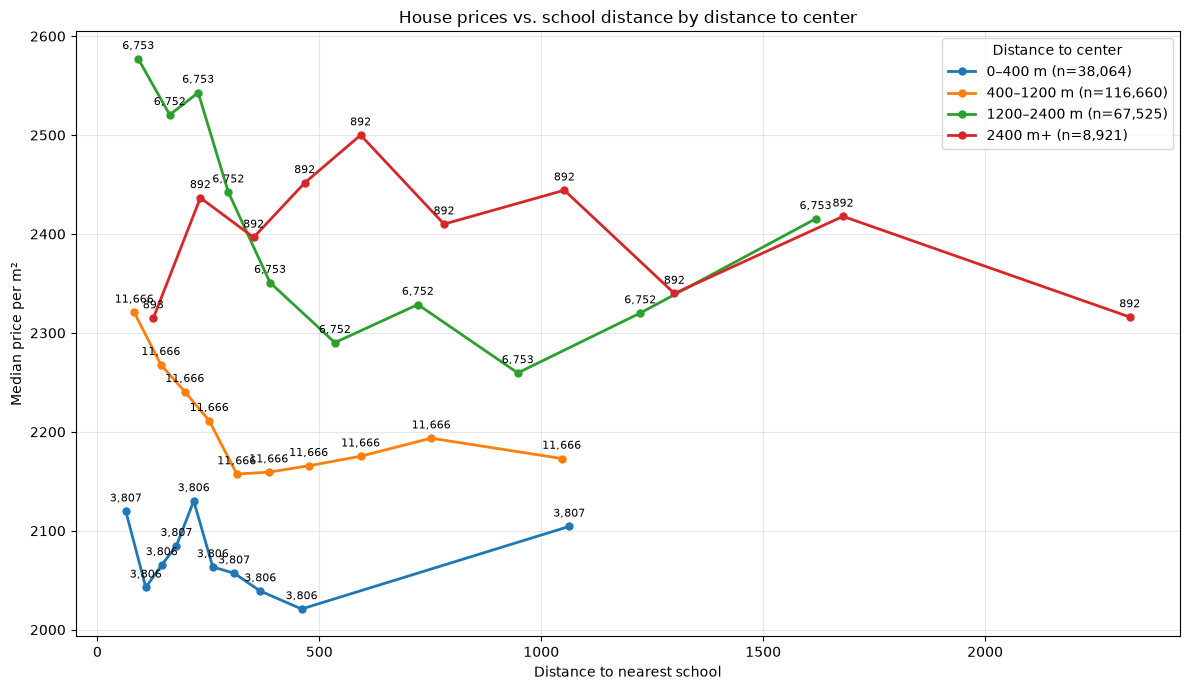

 center_bin  school_distance   median_ppm  house_count
    0–400 m             64.0  2119.705489         3807
    0–400 m            109.0  2042.761528         3806
    0–400 m            145.0  2065.480752         3806
    0–400 m            178.0  2084.825026         3807
    0–400 m            217.0  2130.160122         3806
    0–400 m            260.0  2063.376382         3806
    0–400 m            308.0  2057.116921         3807
    0–400 m            367.0   2039.05482         3806
    0–400 m            460.0  2020.919468         3806
    0–400 m           1063.0  2104.387388         3807
1200–2400 m             92.0  2577.081563         6753
1200–2400 m            163.0  2520.474141         6752
1200–2400 m            227.0  2543.001771         6753
1200–2400 m            295.0   2442.28478         6752
1200–2400 m            389.0  2350.838252         6753
1200–2400 m            535.0  2290.213406         6752
1200–2400 m            722.0  2328.701712         6752
1200–2400 

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

d = df.query("housingType == 'HOUSE'").copy()

d["ppm"] = pd.to_numeric(d["price/m2hab_adj"], errors="coerce")
d["center"] = pd.to_numeric(d["distanceToNearestCenter"], errors="coerce")
d["school"] = pd.to_numeric(d["schoolDistance"], errors="coerce")

d = d.dropna(subset=["ppm", "school", "center"])

# Fixed distance-to-center buckets
center_bins = [0, 400, 1200, 2400, float("inf")]
center_labels = ["0–400 m", "400–1200 m", "1200–2400 m", "2400 m+"]

d["center_bin"] = pd.cut(
    d["center"],
    bins=center_bins,
    labels=center_labels,
    right=False,
    include_lowest=True
)

d = d.dropna(subset=["center_bin"])

# Create 10 approximately equal-sized groups within each center bucket
n_points = 10
summaries = []

for label in center_labels:
    group = d[d["center_bin"] == label].copy()

    if group.empty:
        continue

    # Rank first to handle repeated school distances more robustly
    group["school_bin"] = pd.qcut(
        group["school"].rank(method="first"),
        q=min(n_points, len(group)),
        labels=False
    )

    summary_group = (
        group.groupby("school_bin")
        .agg(
            school_distance=("school", "median"),
            median_ppm=("ppm", "median"),
            house_count=("ppm", "size")
        )
        .reset_index()
    )

    summary_group["center_bin"] = label
    summaries.append(summary_group)

summary = pd.concat(summaries, ignore_index=True)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

for label in center_labels:
    subset = (
        summary[summary["center_bin"] == label]
        .sort_values("school_distance")
    )

    if subset.empty:
        continue

    ax.plot(
        subset["school_distance"],
        subset["median_ppm"],
        marker="o",
        markersize=5,
        linewidth=2,
        label=f"{label} (n={d[d['center_bin'] == label].shape[0]:,})"
    )

    # Show house count at each point
    for _, row in subset.iterrows():
        ax.annotate(
            f"{int(row['house_count']):,}",
            (row["school_distance"], row["median_ppm"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

ax.set_xlabel("Distance to nearest school")
ax.set_ylabel("Median price per m²")
ax.set_title("House prices vs. school distance by distance to center")
ax.grid(True, alpha=0.3)
ax.legend(title="Distance to center")
plt.tight_layout()
plt.show()

# Check the number of houses per plotted point
print(
    summary[["center_bin", "school_distance", "median_ppm", "house_count"]]
    .sort_values(["center_bin", "school_distance"])
    .to_string(index=False)
)

#Verandert de mScore? 
In de grafiek hieronder zie je dat binnenin dezelfde prijscategorie de mScore weinig verandert -> dezelfde locaties blijven even aantrekkelijk. 
Grootste variaties in top (1%) (waarschijnlijk door kleiner aanbod) en bottom 50% (waarschijnlijk doordat hier grotere verschillenn opzitten)

plot_data(
    data=df,
    x="lastListing",
    y="price/m2hab_adj",
    bucket_col = "mScore",
    split_by=["yearly_bucket"],
    bucket_by_year=True,
    bucket_percentiles=[0.50, 0.75, 1.0],
    bucket_labels=[
        "Bottom 50%",
        "50–75%",
        "Top 25%",
    ],
    
    agg="mean",
    where={"housingType": "HOUSE"},
    freq="YE",
)

# Schoolafstand is belangrijk 

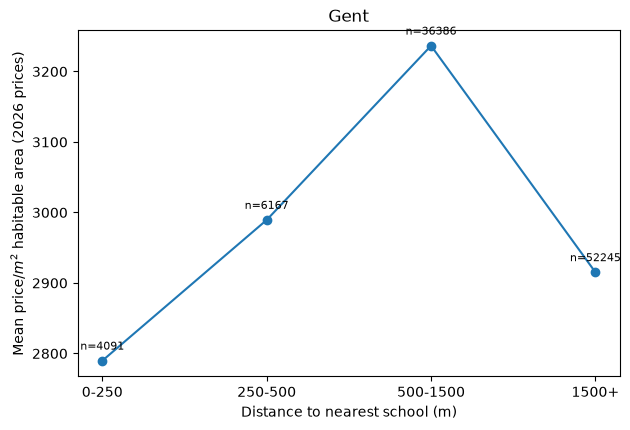

                          mean   size
trainStopDistance                    
0-250              2789.658855   4091
250-500            2989.347158   6167
500-1500           3236.509609  36386
1500+              2915.126558  52245


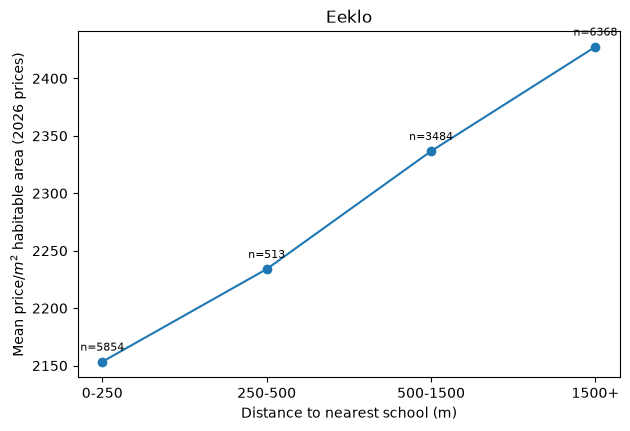

                          mean  size
trainStopDistance                   
0-250              2153.362022  5854
250-500            2234.013147   513
500-1500           2336.671832  3484
1500+              2427.570324  6368


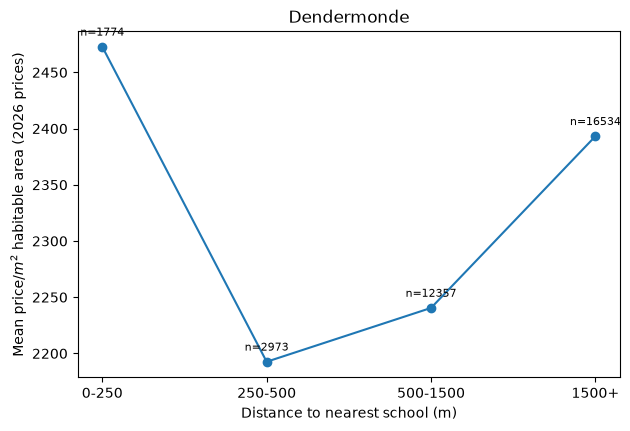

                          mean   size
trainStopDistance                    
0-250              2472.803531   1774
250-500            2192.586186   2973
500-1500           2240.471864  12357
1500+              2393.261162  16534


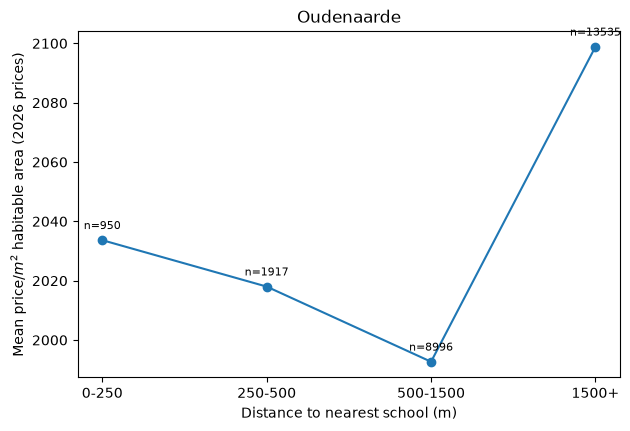

                          mean   size
trainStopDistance                    
0-250              2033.661061    950
250-500             2018.01164   1917
500-1500           1992.678151   8996
1500+              2098.855472  13535


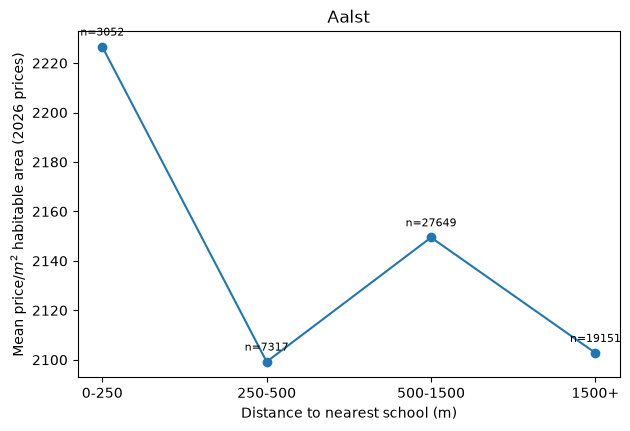

                          mean   size
trainStopDistance                    
0-250               2226.60177   3052
250-500             2099.20847   7317
500-1500           2149.468822  27649
1500+              2102.741559  19151


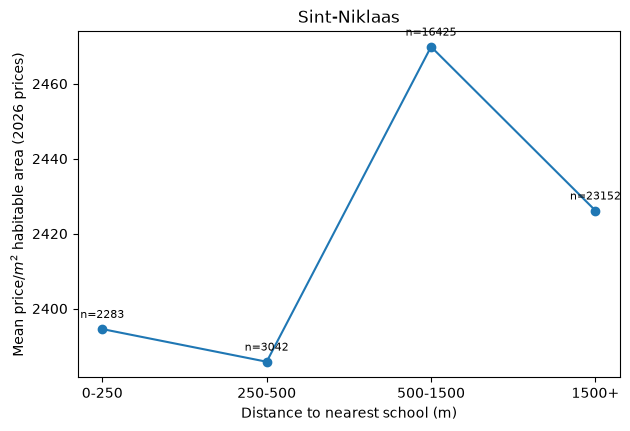

                          mean   size
trainStopDistance                    
0-250              2394.534374   2283
250-500            2385.811311   3042
500-1500           2469.868965  16425
1500+              2426.134894  23152


In [20]:


edges  = [0,  250, 500, 1500, float('inf')]
labels = [ '0-250', '250-500', '500-1500', '1500+']

def distance_plot(data, admin2, xcol='trainStopDistance', ycol='price/m2hab_adj'):
    m = data['admin2'].to_numpy() == admin2                 # boolean mask, no copy of the whole frame
    d = data.loc[m, [xcol, ycol]].dropna()

    bucket = pd.cut(d[xcol], bins=edges, labels=labels, right=False)   # [0,100), [100,250), ...
    agg = d.groupby(bucket, observed=False)[ycol].agg(['mean', 'size'])

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(labels, agg['mean'].to_numpy(), 'o-')
    for x, (p, n) in zip(labels, agg.to_numpy()):
        ax.annotate(f"n={int(n)}", (x, p), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
    ax.set_xlabel('Distance to nearest school (m)')
    ax.set_ylabel('Mean price/$m^2$ habitable area (2026 prices)')
    ax.set_title(admin2)
    plt.show()
    return agg

for city in ['Gent', 'Eeklo',  'Dendermonde', 'Oudenaarde', 'Aalst', 'Sint-Niklaas']:
    
    agg = distance_plot(df, admin2 =city)
    print(agg)

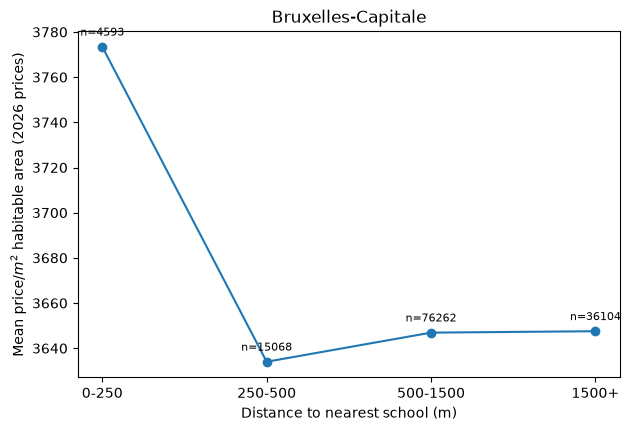

                          mean   size
trainStopDistance                    
0-250              3773.457198   4593
250-500             3634.01751  15068
500-1500           3646.905926  76262
1500+              3647.532444  36104


In [21]:
agg = distance_plot(df, admin2 ='Bruxelles-Capitale')
print(agg)

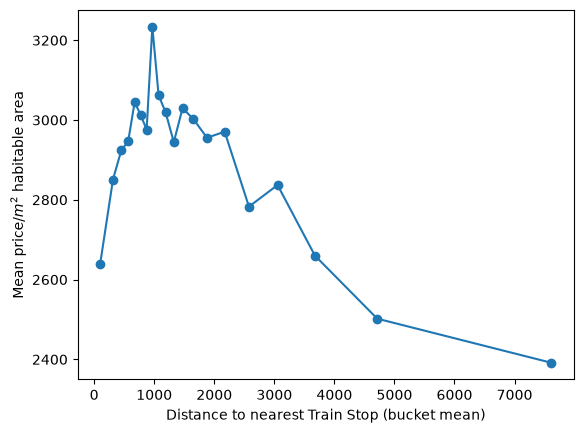

In [22]:
df1= df.dropna(subset=['trainStopDistance', 'price/m2hab_adj'])

# 20 buckets with (roughly) the same number of rows each
df1 = df1.assign(bucket=pd.qcut(df['trainStopDistance'], q=20, duplicates='drop'))

agg = df1.groupby('bucket', observed=True).agg(
    distance=('trainStopDistance', 'mean'),
    price_per_sqm=('price/m2hab_adj', 'mean'),
    n=('price/m2hab_adj', 'size'),
)

plt.plot(agg['distance'], agg['price_per_sqm'], 'o-')
plt.xlabel('Distance to nearest Train Stop (bucket mean)')
plt.ylabel('Mean price/$m^2$ habitable area')
plt.show()

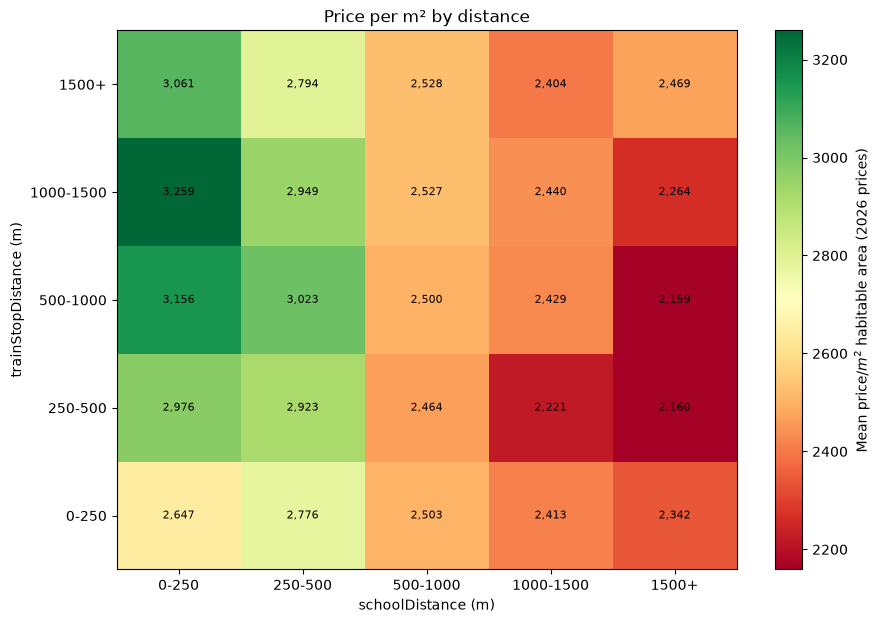

In [23]:
edges  = [0,250,500, 1000, 1500, np.inf]
labels = ['0-250','250-500', '500-1000', '1000-1500', '1500+']

def distance_heatmap(data, xcol='schoolDistance', ycol='trainStopDistance',
                     zcol='price/m2hab_adj', admin1=None, admin2=None, locality=None,
                     admin2without=None, year_only=None, year_begin=None, year_end=None,
                     min_n=10, xedges=edges, yedges=edges, xlabels=labels, ylabels=labels,
                     cmap='RdYlGn', title=None):
    d = data
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    if year_only is not None:                       # exactly this year
        d = d[d['year_last'].to_numpy() == year_only]
    if year_begin is not None:                      # year_begin <= year < year_end
        d = d[d['year_last'].to_numpy() >= year_begin]
    if year_end is not None:
        d = d[d['year_last'].to_numpy() < year_end]

    # numeric only, no NaN / inf / negative distances
    d = d[[xcol, ycol, zcol]].apply(pd.to_numeric, errors='coerce')
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[xcol] >= 0) & (d[ycol] >= 0)]
    if d.empty:
        print("No rows left after filtering"); return None, None

    nx, ny = len(xlabels), len(ylabels)
    # bin index per row: bins are [lower, upper), the last one is open-ended
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    yi = np.digitize(d[ycol].to_numpy(), yedges[1:-1])
    flat = yi * nx + xi

    s = np.bincount(flat, weights=d[zcol].to_numpy(), minlength=nx * ny).reshape(ny, nx)
    n = np.bincount(flat, minlength=nx * ny).reshape(ny, nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)   # hide cells with too few houses

    fig, ax = plt.subplots(figsize=(10, 7))
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad('lightgrey')                                      # cells below min_n
    im = ax.imshow(np.ma.masked_invalid(mean), origin='lower', cmap=cm, aspect='auto')
    fig.colorbar(im, label='Mean price/$m^2$ habitable area (2026 prices)')
    ax.set_xticks(range(nx), xlabels)
    ax.set_yticks(range(ny), ylabels)
    ax.set_xlabel(f'{xcol} (m)')
    ax.set_ylabel(f'{ycol} (m)')
    ax.set_title(title or admin2 or locality or 'Price per m² by distance')

    # price and number of observations in each cell
    for i in range(ny):
        for j in range(nx):
            if n[i, j] >= min_n:
                ax.text(j, i, f"{mean[i, j]:,.0f}", #\n(n={n[i, j]}
                        ha='center', va='center', fontsize=8, color='black')
            else:
                ax.text(j, i, f"n={n[i, j]}", ha='center', va='center', fontsize=8, color='grey')

    plt.show()
    return (pd.DataFrame(mean, index=ylabels, columns=xlabels),
            pd.DataFrame(n, index=ylabels, columns=xlabels))

mean_tbl, n_tbl = distance_heatmap(df)                                   # whole dataset
# mean_tbl, n_tbl = distance_heatmap(df, admin2='Dendermonde')           # one arrondissement
# mean_tbl, n_tbl = distance_heatmap(df, year_begin=2023, year_end=2026) # 2023, 2024 and 2025

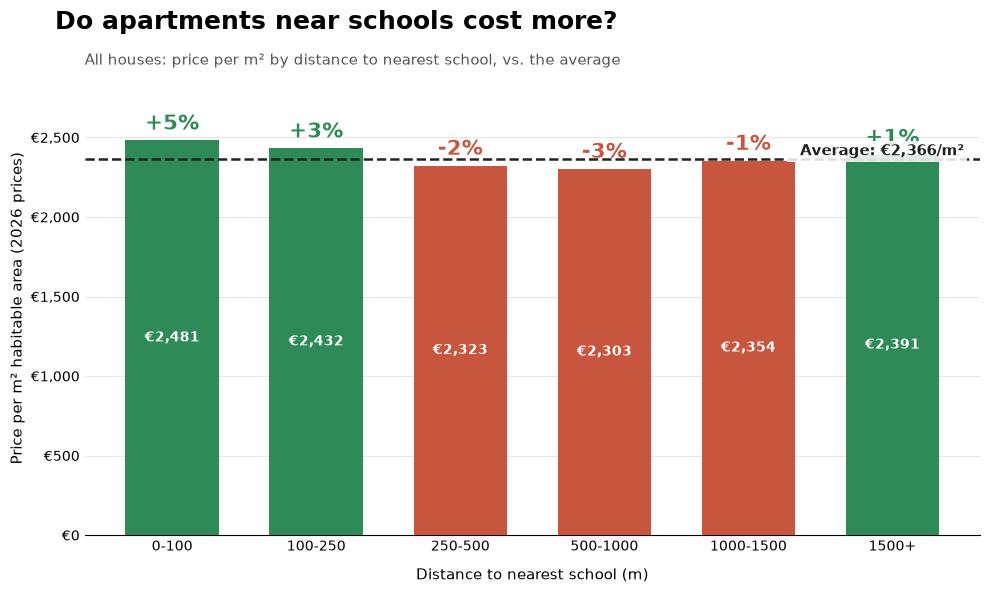

,mean_price,pct_vs_avg,n
0-100,2481.179011,0.048833,17744
100-250,2431.546043,0.027852,63334
250-500,2323.093381,-0.017992,69882
500-1000,2303.327816,-0.026348,52541
1000-1500,2353.812176,-0.005007,18110
1500+,2390.873324,0.010659,9559


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

edges  = [0.1, 100, 250, 500, 1000, 1500, np.inf]
labels = ['0-100', '100-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='schoolDistance', zcol='price/m2hab_adj',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: €{overall:,.0f}/m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.0%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'€{m:,.0f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest school (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Price per m² habitable area (2026 prices)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'€{v:,.0f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Do apartments near schools cost more?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: price per m² by distance to nearest school, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_price': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'])
tbl

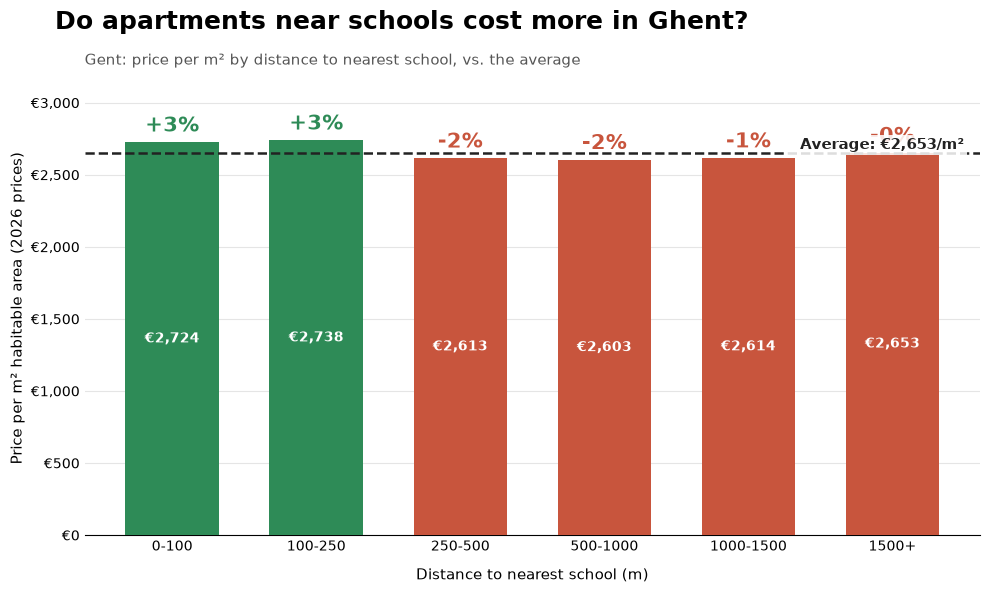

,mean_price,pct_vs_avg,n
0-100,2724.420040,0.026753,4803
100-250,2738.051659,0.031891,16990
250-500,2613.250024,-0.015143,18910
500-1000,2603.065203,-0.018982,15871
1000-1500,2614.303690,-0.014746,5576
1500+,2652.974781,-0.000172,2738


In [25]:
from matplotlib.ticker import FuncFormatter

edges  = [0.1, 100, 250, 500, 1000, 1500, np.inf]
labels = ['0-100', '100-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='schoolDistance', zcol='price/m2hab_adj',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: €{overall:,.0f}/m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.0%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'€{m:,.0f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest school (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Price per m² habitable area (2026 prices)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'€{v:,.0f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Do apartments near schools cost more in Ghent?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: price per m² by distance to nearest school, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_price': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'],admin2='Gent')
tbl

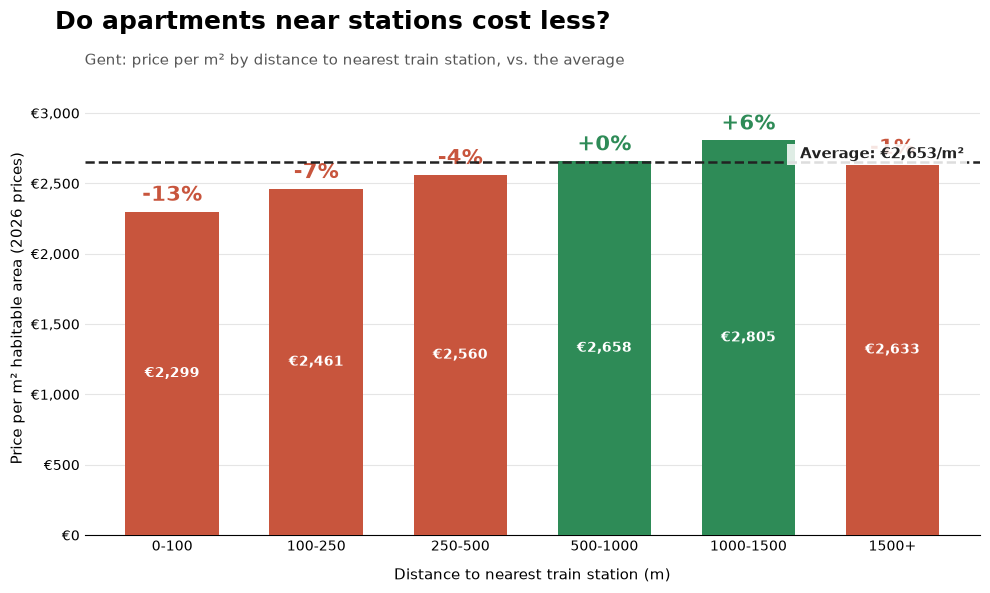

,mean_size,pct_vs_avg,n
0-100,2298.973740,-0.133585,713
100-250,2460.553602,-0.072690,1217
250-500,2560.219396,-0.035129,3664
500-1000,2657.539132,0.001548,10643
1000-1500,2805.316005,0.057241,10329
1500+,2632.986050,-0.007705,38322


In [26]:
from matplotlib.ticker import FuncFormatter

edges  = [0.1, 100, 250, 500, 1000, 1500, np.inf]
labels = ['0-100', '100-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='trainStopDistance', zcol='price/m2hab_adj',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: €{overall:,.0f}/m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.0%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'€{m:,.0f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest train station (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Price per m² habitable area (2026 prices)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'€{v:,.0f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Do apartments near stations cost less?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: price per m² by distance to nearest train station, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_size': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'],admin2='Gent')
tbl

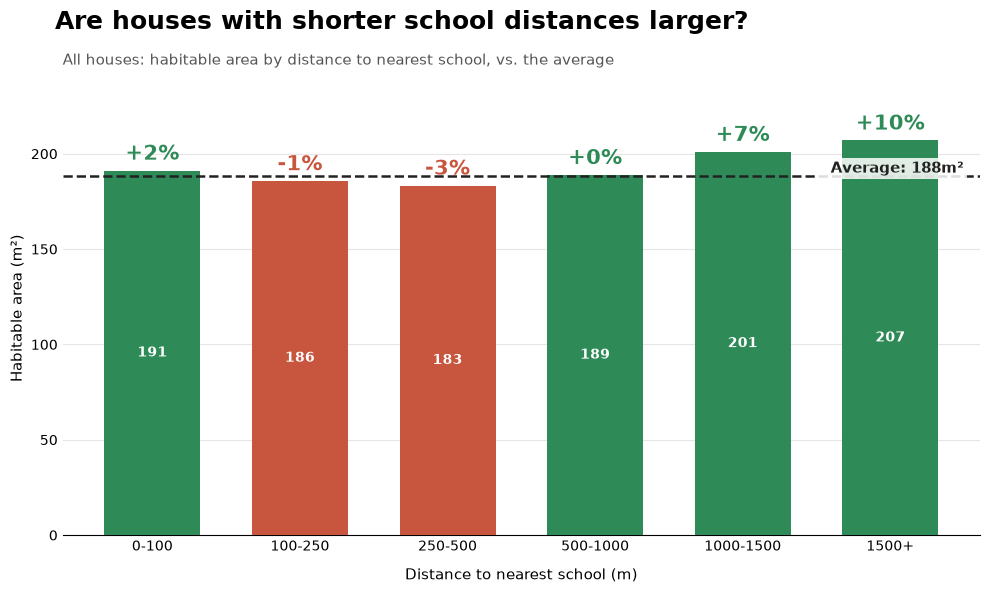

,mean_size,pct_vs_avg,n
0-100,191.170923,0.015872,18131
100-250,185.652457,-0.013453,64582
250-500,183.293332,-0.025989,71223
500-1000,188.872123,0.003656,53481
1000-1500,200.998705,0.068096,18536
1500+,206.954750,0.099746,9768


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

edges  = [1, 100, 250, 500, 1000, 1500, np.inf]
labels = ['0-100', '100-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='schoolDistance', zcol='habitableArea',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: {overall:,.0f}m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.0%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'{m:,.0f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest school (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Habitable area (m²)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Are houses with shorter school distances larger?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: habitable area by distance to nearest school, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_size': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'])
tbl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

edges  = [0, 100, 250, 500, 1500, np.inf]
labels = ['0-100', '100-250', '250-500', '500-1500', '1500+']

def distance_heatmap(data, xcol='schoolDistance', ycol='busStopDistance',
                     zcol='price/m2hab_adj', admin2=None, min_n=10,
                     xedges=edges, yedges=edges, xlabels=labels, ylabels=labels,
                     cmap='RdYlGn'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    d = d[[xcol, ycol, zcol]].dropna()

    nx, ny = len(xlabels), len(ylabels)
    # bin index per row: bins are [lower, upper), the last one is open-ended
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    yi = np.digitize(d[ycol].to_numpy(), yedges[1:-1])
    flat = yi * nx + xi

    s = np.bincount(flat, weights=d[zcol].to_numpy(), minlength=nx * ny).reshape(ny, nx)
    n = np.bincount(flat, minlength=nx * ny).reshape(ny, nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)   # hide cells with too few houses

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(np.ma.masked_invalid(mean), origin='lower', cmap=cmap, aspect='auto')
    fig.colorbar(im, label='Mean price/$m^2$ habitable area (2026 prices)')
    ax.set_xticks(range(nx), xlabels)
    ax.set_yticks(range(ny), ylabels)
    ax.set_xlabel('Distance to nearest school (m)')
    ax.set_ylabel('Distance to nearest bus stop (m)')
    ax.set_title(admin2 or 'All data')

    # show price and number of houses in each cell
    for r in range(ny):
        for c in range(nx):
            if n[r, c] >= min_n:
                ax.text(c, r, f"{mean[r, c]:.0f}\n(n={n[r, c]})", ha='center', va='center', fontsize=8)
    plt.show()
    return pd.DataFrame(mean, index=ylabels, columns=xlabels), pd.DataFrame(n, index=ylabels, columns=xlabels)

mean_tbl, n_tbl = distance_heatmap(df)                       # whole dataset
mean_tbl, n_tbl = distance_heatmap(df, admin2='Dendermonde')  # one arrondissement

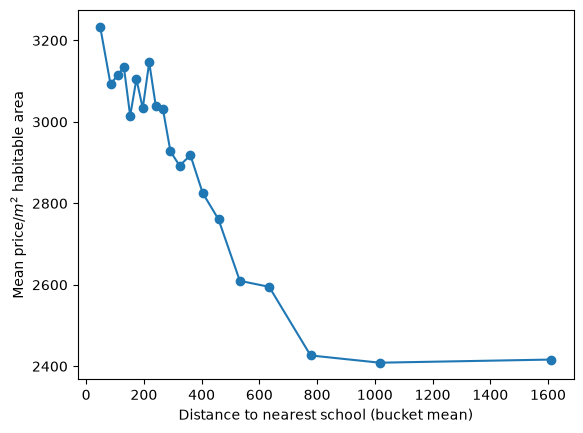

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

df2 = df.dropna(subset=['schoolDistance', 'price/m2hab_adj'])

# 20 buckets with (roughly) the same number of rows each
df2 = df2.assign(bucket=pd.qcut(df['schoolDistance'], q=20, duplicates='drop'))

agg = df2.groupby('bucket', observed=True).agg(
    distance=('schoolDistance', 'mean'),
    price=('price/m2hab_adj', 'mean'),
    n=('price/m2hab_adj', 'size'),
)

plt.plot(agg['distance'], agg['price'], 'o-')
plt.xlabel('Distance to nearest school (bucket mean)')
plt.ylabel('Mean price/$m^2$ habitable area')
plt.show()

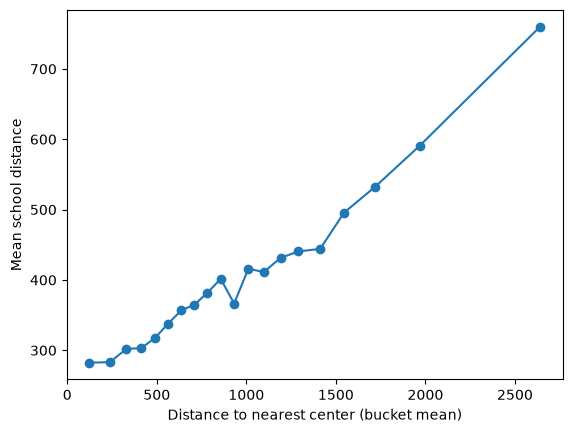

In [29]:
df = data_prices.dropna(subset=['distanceToNearestCenter', 'schoolDistance'])

# 20 buckets with (roughly) the same number of rows each
df = df.assign(bucket=pd.qcut(df['distanceToNearestCenter'], q=20, duplicates='drop'))

agg = df.groupby('bucket', observed=True).agg(
    distance=('distanceToNearestCenter', 'mean'),
    school_distance=('schoolDistance', 'mean'),
    n=('schoolDistance', 'size'),
)

plt.plot(agg['distance'], agg['school_distance'], 'o-')
plt.xlabel('Distance to nearest center (bucket mean)')
plt.ylabel('Mean school distance')
plt.show()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def price_heatmap(data, xcol, ycol='distanceToNearestCenter', zcol='price/m2hab',
                  nx=20, ny=20, min_n=5,
                  xscale='symlog', yscale='symlog',
                  xlin=None, ylin=None):
    df = data[[xcol, ycol, zcol]].apply(pd.to_numeric, errors='coerce').dropna()
    if df.empty:
        print("No rows left after filtering"); return

    xb, xedges = pd.qcut(df[xcol], q=nx, labels=False, retbins=True, duplicates='drop')
    yb, yedges = pd.qcut(df[ycol], q=ny, labels=False, retbins=True, duplicates='drop')
    n_x, n_y = len(xedges) - 1, len(yedges) - 1

    g = df.groupby([yb.rename('yb'), xb.rename('xb')])[zcol].agg(['mean', 'size']).reset_index()
    g = g[g['size'] >= min_n]

    z = np.full((n_y, n_x), np.nan)
    z[g['yb'].astype(int), g['xb'].astype(int)] = g['mean']

    fig, ax = plt.subplots(figsize=(10, 7))
    mesh = ax.pcolormesh(xedges, yedges, np.ma.masked_invalid(z), cmap='viridis')
    fig.colorbar(mesh, label=f'Mean {zcol}')
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)

    def apply_scale(axis_set, kind, lin, edges):
        if kind == 'symlog':
            # linear below `lin`, log above; default: the first non-zero edge
            lin = lin or max(edges[edges > 0].min(), 1e-6)
            axis_set('symlog', linthresh=lin)
        elif kind == 'asinh':
            lin = lin or max(edges[edges > 0].min(), 1e-6)
            axis_set('asinh', linear_width=lin)
        else:
            axis_set(kind)

    apply_scale(ax.set_xscale, xscale, xlin, xedges)
    apply_scale(ax.set_yscale, yscale, ylin, yedges)
    plt.show()
    plt.close(fig)

houses = data_prices[data_prices['housingType'] == 'APARTMENT']

price_heatmap(houses, 'schoolDistance', xscale='asinh', yscale='asinh')

mScore en distance To nearest center izjn verschillend 
-> dure huizen hebben hoge mscore maar zijn niet perse in het centrum 
-> liever goede nabijheid dan drukte? 

# BRUSSELS MAP

In [18]:
from dotenv import load_dotenv
import os


OPENAI_API_KEY='cb1_4r9c_1_6c4137313fd9cf4b83bc4b44'

load_dotenv()
key = os.getenv("OPENAI_API_KEY")

In [ ]:
# pip install folium branca pyproj scipy
import re, numpy as np, pandas as pd, folium
import branca.colormap as cm
from pyproj import Transformer
from scipy.spatial import cKDTree

ZCOL   = 'price/m2hab_adj'
EDGES  = [ 250, 500, 1000, 1500]
LABELS = ['0-250', '250-500', '500-1000', '1000-1500']
BXL_BBOX = (4.24, 50.76, 4.50, 50.92)          # west, south, east, north

NR     = len(EDGES)          # <- add this line (number of rings = 4)


# ---------- 1. stations from your csv ----------
def load_stations(path='stations_bxl.csv'):
    rows = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            m = re.search(r'coordinates\W+\[\s*([-\d.]+)\s*,\s*([-\d.]+)\s*\]', line)
            if m:
                parts = line.split(';')
                rows.append({'name': parts[1].strip('"'),
                             'lon': float(m.group(1)), 'lat': float(m.group(2))})
    return pd.DataFrame(rows).drop_duplicates(['lon', 'lat']).reset_index(drop=True)

# ---------- 2. houses from df['marker'] ----------
def prepare_houses(df, zcol=ZCOL, bbox=BXL_BBOX):
    d = df.copy()
    ll = d['marker'].astype(str).str.extract(r'POINT\s*\(\s*([-\d.eE+]+)\s+([-\d.eE+]+)\s*\)')
    d['lon'] = pd.to_numeric(ll[0]); d['lat'] = pd.to_numeric(ll[1])
    d = d.dropna(subset=['lon', 'lat', zcol])
    w, s, e, n = bbox
    return d[d['lon'].between(w, e) & d['lat'].between(s, n)]

# ---------- 3. distance to nearest station + ring ----------
def assign_rings(houses, stations):
    tr = Transformer.from_crs(4326, 31370, always_xy=True)      # Belgian Lambert 72 (metres)
    hx, hy = tr.transform(houses['lon'].values, houses['lat'].values)
    sx, sy = tr.transform(stations['lon'].values, stations['lat'].values)
    dist, idx = cKDTree(np.c_[sx, sy]).query(np.c_[hx, hy])
    h = houses.copy()
    h['station_idx'] = idx
    h['station_dist'] = dist
    h['ring'] = np.digitize(dist, EDGES)                        # 0..4 = rings, 5 = outside 1500 m
    return h

# ---------- 4. map ----------
def station_ring_map(
    h,
    stations,
    zcol=ZCOL,
    min_n=3,
    per_station=True,
    opacity=0.4
):
    # Only houses within 1500 m of their nearest station
    inside = h[h['ring'] < NR].copy()

    # Average price within the full 1500 m area of each station
    if per_station:
        circle_avg = inside.groupby('station_idx')[zcol].mean()
        inside['ref'] = inside['station_idx'].map(circle_avg)
    else:
        overall_circle_avg = inside[zcol].mean()
        inside['ref'] = overall_circle_avg

    # Percentage difference from the 1500 m reference average
    inside['pct'] = (inside[zcol] / inside['ref'] - 1) * 100

    # Mean price and sample size for every station and ring
    st_ring = inside.groupby(['station_idx', 'ring']).agg(
        mean_price=(zcol, 'mean'),
        n=(zcol, 'size'),
        pct=('pct', 'mean')
    )

    # Ring mean compared with the full 1500 m average
    if per_station:
        st_ring['ref'] = (
            circle_avg.reindex(
                st_ring.index.get_level_values('station_idx')
            ).to_numpy()
        )
        st_ring['pct'] = (
            st_ring['mean_price'] / st_ring['ref'] - 1
        ) * 100
    else:
        st_ring['ref'] = overall_circle_avg
        st_ring['pct'] = (
            st_ring['mean_price'] / overall_circle_avg - 1
        ) * 100

    # Exclude rings with too few houses
    valid = st_ring[st_ring['n'] >= min_n].copy()

    if valid.empty:
        raise ValueError(
            "No station/ring combinations have enough houses. "
            "Try reducing min_n."
        )

    # Symmetric color scale centered on 0%
    lim = max(
        float(np.nanpercentile(valid['pct'].abs(), 95)),
        1.0
    )

    cmap = cm.LinearColormap(
        ['#D7191C', '#FFDD57', '#1A9641'],      # red (cheaper) -> yellow (average) -> green (more expensive)
        vmin=-lim,
        vmax=lim,
        caption=(
            'Price per m² vs. average price within the same '
            'station’s 1500 m area (%) · red = cheaper, green = more expensive'
        )
    )
        

    m = folium.Map(
        location=[50.835, 4.36],
        zoom_start=12,
        tiles='OpenStreetMap',
        control_scale=True
    )

    rings_layer = folium.FeatureGroup(
        name='Station rings',
        show=True
    ).add_to(m)

    # Draw larger rings first so smaller rings remain visible
    for ring in reversed(range(NR)):
        for i, s in stations.iterrows():

            if (i, ring) not in valid.index:
                continue

            r = valid.loc[(i, ring)]

            mean = float(r['mean_price'])
            pct = float(r['pct'])
            n = int(r['n'])
            ref = float(r['ref'])

            color = cmap(float(np.clip(pct, -lim, lim)))

            if not isinstance(color, str) or not color.startswith('#'):
                color = '#F7F7F7'

            folium.Circle(
                location=(s['lat'], s['lon']),
                radius=EDGES[ring],
                color='white',
                weight=0.6,
                fill=True,
                fill_color=color,
                fill_opacity=opacity,
                tooltip=(
                    f"{s['name']} · {LABELS[ring]} m · "
                    f"{pct:+.1f}% vs 1500 m average · "
                    f"€{mean:,.0f}/m² vs €{ref:,.0f}/m² · "
                    f"n={n}"
                )
            ).add_to(rings_layer)

    # Station markers
    for _, s in stations.iterrows():
        folium.CircleMarker(
            location=(s['lat'], s['lon']),
            radius=5,
            color='black',
            weight=1.5,
            fill=True,
            fill_color='white',
            fill_opacity=1,
            tooltip=s['name']
        ).add_to(m)

    cmap.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)

    # City-wide summary table
    table = inside.groupby('ring').agg(
        mean_price=(zcol, 'mean'),
        n=(zcol, 'size')
    )

    if per_station:
        # Average the station-specific ring percentages, giving
        # each station/ring combination equal weight.
        summary = valid.groupby(level='ring')['pct'].mean()
        table['pct_vs_circle'] = summary.reindex(table.index)
    else:
        table['pct_vs_circle'] = (
            table['mean_price'] / overall_circle_avg - 1
        ) * 100

    table.index = [LABELS[int(r)] for r in table.index]

    return m, table

stations = load_stations('stations_bxl_all.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'])
h        = assign_rings(houses, stations)
print(len(stations), 'stations,', len(houses), 'houses')

m, table = station_ring_map(h, stations, per_station=True)    # False = same colour per ring everywhere
m.save('brussels_station_rings_busy.html')
display(table)      # Brussels-wide mean per ring, as in your school bar chart
m

33 stations, 35419 houses


,mean_price,n,pct_vs_circle
0-250,3154.60498,1285,1.111809
250-500,2918.996205,5606,-2.909268
500-1000,3030.353542,11752,0.311477
1000-1500,3116.641272,6987,2.430797


# Gent Map

In [ ]:
# pip install folium branca pyproj scipy
import re, numpy as np, pandas as pd, folium
import branca.colormap as cm
from pyproj import Transformer
from scipy.spatial import cKDTree

ZCOL   = 'price/m2hab_adj'
EDGES  = [250, 500, 1000, 1500]
LABELS = ['0-250', '250-500', '500-1000', '1000-1500']
NR     = len(EDGES)
GENT_BBOX   = (3.55, 50.95, 3.90, 51.15)     # west, south, east, north (covers all 10 stations + 1500 m)
GENT_CENTER = (51.045, 3.725)

# ---------- 1. stations: id;name;coordinates  ->  1;"Gent-Sint-Pieters";[3.71072, 51.03552] ----------
def load_stations(path='stations_ghent.csv'):
    rows = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            m = re.match(r'\s*(\d+)\s*;\s*"?([^";]+)"?\s*;\s*\[\s*([-\d.]+)\s*,\s*([-\d.]+)\s*\]', line)
            if m:
                rows.append({'name': m.group(2).strip(),
                             'lon': float(m.group(3)), 'lat': float(m.group(4))})
    return pd.DataFrame(rows).reset_index(drop=True)

# ---------- 2. houses from df['marker'] ----------
def prepare_houses(df, zcol=ZCOL, bbox=GENT_BBOX):
    d = df.copy()
    ll = d['marker'].astype(str).str.extract(r'POINT\s*\(\s*([-\d.eE+]+)\s+([-\d.eE+]+)\s*\)')
    d['lon'] = pd.to_numeric(ll[0]); d['lat'] = pd.to_numeric(ll[1])
    d = d.dropna(subset=['lon', 'lat', zcol])
    w, s, e, n = bbox
    return d[d['lon'].between(w, e) & d['lat'].between(s, n)]

# ---------- 3. nearest station + ring ----------
def assign_rings(houses, stations):
    tr = Transformer.from_crs(4326, 31370, always_xy=True)      # Belgian Lambert 72 (metres)
    hx, hy = tr.transform(houses['lon'].values, houses['lat'].values)
    sx, sy = tr.transform(stations['lon'].values, stations['lat'].values)
    dist, idx = cKDTree(np.c_[sx, sy]).query(np.c_[hx, hy])
    h = houses.copy()
    h['station_idx'], h['station_dist'] = idx, dist
    h['ring'] = np.digitize(dist, EDGES)                        # 0..NR-1 = rings, NR = outside 1500 m
    return h

# ---------- 4. map ----------
def station_ring_map(h, stations, zcol=ZCOL, min_n=3, per_station=True, opacity=0.5):
    inside = h[h['ring'] < NR].copy()

    # average of the whole 1500 m circle (per station, or one city-wide value)
    if per_station:
        inside['ref'] = inside.groupby('station_idx')[zcol].transform('mean')
        circle_avg = inside.groupby('station_idx')[zcol].mean()
    else:
        inside['ref'] = inside[zcol].mean()
    inside['rel'] = inside[zcol] / inside['ref'] - 1            # 4000 vs 3000 -> +0.33

    st_ring = inside.groupby(['station_idx', 'ring']).agg(price=(zcol, 'mean'), rel=('rel', 'mean'),
                                                           n=(zcol, 'size'))
    if per_station:
        st_ring['pct'] = st_ring['price'] / circle_avg.reindex(st_ring.index.get_level_values(0)).values - 1
    else:
        st_ring['pct'] = st_ring['price'] / inside[zcol].mean() - 1

    valid = st_ring[st_ring['n'] >= min_n]
    lim = max(float(np.nanpercentile(valid['pct'].abs() * 100, 95)), 1)
    cmap = cm.LinearColormap(
        colors=['#B2182B', '#F7F7F7', '#1A9850'],
        vmin=-lim,
        vmax=lim,
        caption='Price per m² vs. average of the 1500 m circle (%)'
    )

    m = folium.Map(
        location=[51.0543, 3.7174],  # Ghent city center
        zoom_start=12,
        tiles='OpenStreet',
        control_scale=True,
    )

    folium.TileLayer(
        tiles="https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png",
        attr="© OpenStreetMap contributors © CARTO",
        name="CARTO Voyager",
        overlay=False,
        control=True,
    ).add_to(m)

    layer = folium.FeatureGroup(name='Station rings', show=True).add_to(m)
    for ring in reversed(range(NR)):                            # big circles first, small on top
        for i, s in stations.iterrows():
            if (i, ring) not in valid.index:
                continue
            r = valid.loc[(i, ring)]
            ref = circle_avg[i] if per_station else inside[zcol].mean()
            folium.Circle((s['lat'], s['lon']), radius=EDGES[ring], color='white', weight=0.6,
                          fill=True, fill_color=cmap(float(np.clip(r['pct'] * 100, -lim, lim))),
                          fill_opacity=opacity,
                          tooltip=(f"{s['name']} · {LABELS[ring]} m · {r['pct']:+.0%} vs 1500 m average "
                                   f"(€{r['price']:,.0f} vs €{ref:,.0f}/m²) · n={int(r['n'])}")).add_to(layer)

    for _, s in stations.iterrows():
        folium.CircleMarker((s['lat'], s['lon']), radius=5, color='black', weight=1.5,
                            fill=True, fill_color='white', fill_opacity=1,
                            tooltip=s['name']).add_to(m)

    cmap.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)

    # table: all houses per ring, compared with their own station's 1500 m average
    table = inside.groupby('ring').agg(mean_price=(zcol, 'mean'), pct_vs_circle=('rel', 'mean'),
                                       n=(zcol, 'size')).reindex(range(NR))
    table.index = LABELS
    return m, table

# ================= RUN =================
stations = load_stations('stations_ghent.csv')
print(stations)
houses = prepare_houses(df)
h      = assign_rings(houses, stations)
print(len(stations), 'stations,', len(houses), 'houses')

m, table = station_ring_map(h, stations, per_station=True)     # False = one city-wide 1500 m average
m.save('ghent_station_rings.html')
display(table)
m

                name      lon       lat
0  Gent-Sint-Pieters  3.71072  51.03552
1      Gent-Dampoort  3.74029  51.05588
2         Gentbrugge  3.75629  51.03863
3          Wondelgem  3.71961  51.08903
4            Drongen  3.65300  51.04700
5          Merelbeke  3.74600  51.00300
6           De Pinte  3.65600  50.99300
7              Melle  3.79900  51.00200
8            Evergem  3.70700  51.11300
9           Landegem  3.62300  51.07800
10 stations, 75069 houses


,mean_price,pct_vs_circle,n
0-250,3102.98226,-0.037582,1151
250-500,3138.804407,-0.071468,3656
500-1000,3274.414039,-0.015046,10795
1000-1500,3452.363767,0.033285,14029


# SCHOOLS Gent

In [ ]:

import json
import re
import folium
import h3
import branca.colormap as cm

from folium.plugins import Fullscreen, MiniMap


# ============================================================
# CONFIGURATION
# ============================================================



# H3 resolution:
# 8 = larger hexagons; 9 = more detail; 10 = smaller hexagons
HEX_RESOLUTION = 8

# Approximate bounds for Ghent
GENT_BOUNDS = [
    [50.95, 3.55],  # southwest: latitude, longitude
    [51.15, 3.90],  # northeast
]

GENT_CENTER = [51.045, 3.725]
PRICE_COL = 'price/m2hab_adj'

SCHOOLS_FILE = 'scholen_gent.csv'
SECONDARY_FILE='scholen_gent_secundair.csv'
# ============================================================
# 1. LOAD HOUSE DATA
# ============================================================

# Assumes df already exists in your notebook.
# Otherwise load your house dataset here:
#
# df = pd.read_csv(HOUSES_FILE)

def prepare_houses(df, price_col=PRICE_COL):
    d = df.copy()

    if "marker" not in d.columns:
        raise ValueError("House data must contain a 'marker' column.")

    if price_col not in d.columns:
        raise ValueError(f"Missing price column: {price_col}")

    # Parse WKT geometry: POINT (longitude latitude)
    coords = d["marker"].astype(str).str.extract(
        r"POINT\s*\(\s*([-+\d.eE]+)\s+([-+\d.eE]+)\s*\)"
    )

    d["lon"] = pd.to_numeric(coords[0], errors="coerce")
    d["lat"] = pd.to_numeric(coords[1], errors="coerce")

    # Allow prices stored as strings, including currency symbols.
    price = (
        d[price_col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .str.replace(r"[^\d.\-+eE]", "", regex=True)
    )

    d[price_col] = pd.to_numeric(price, errors="coerce")

    # Keep valid locations and positive prices.
    d = d.dropna(subset=["lon", "lat", price_col])
    d = d[
        (d["lon"].between(3.55, 3.90))
        & (d["lat"].between(50.95, 51.15))
        & (d[price_col] > 0)
        & np.isfinite(d[price_col])
    ].copy()

    if d.empty:
        raise ValueError(
            "No valid houses found. Check your marker format and price column."
        )

    # Assign every house to a geographic hexagon.
    d["hex_id"] = [
        h3.latlng_to_cell(lat, lon, HEX_RESOLUTION)
        for lat, lon in zip(d["lat"], d["lon"])
    ]

    return d.reset_index(drop=True)


# ============================================================
# 2. LOAD SCHOOL DATA
# ============================================================


def prepare_schools_secondary(path=SECONDARY_FILE):
    # Source CSV uses semicolons as delimiters.
    schools = pd.read_csv(
        path,
        sep=";",
        encoding="utf-8-sig",
        dtype=str,
        on_bad_lines="warn",
    )

    schools.columns = schools.columns.str.strip()

    def parse_school_location(row):
        # Support both old and new CSV column names.
        shape = row.get("Geometry")
        if pd.isna(shape):
            shape = row.get("Geo Shape")

        # Preferred source: GeoJSON geometry.
        if pd.notna(shape):
            try:
                geometry = json.loads(shape)

                if geometry.get("type") == "Point":
                    lon, lat = geometry["coordinates"]
                    return float(lat), float(lon)
            except (ValueError, TypeError, KeyError):
                pass

        # Support both old and new point column names.
        point = row.get("geo_point_2d")
        if pd.isna(point):
            point = row.get("Geo Point")

        # Fallback: "latitude, longitude"
        if pd.notna(point):
            match = re.search(
                r"^\s*([-+\d.eE]+)\s*,\s*([-+\d.eE]+)\s*$",
                str(point),
            )

            if match:
                return float(match.group(1)), float(match.group(2))

        return np.nan, np.nan

    locations = schools.apply(parse_school_location, axis=1)

    schools["lat"] = [p[0] for p in locations]
    schools["lon"] = [p[1] for p in locations]

    schools = schools.dropna(subset=["lat", "lon"]).copy()

    # Keep schools within the Ghent area.
    schools = schools[
        schools["lon"].between(3.55, 3.90)
        & schools["lat"].between(50.95, 51.15)
    ].copy()

    return schools.reset_index(drop=True)


def prepare_schools(path=SCHOOLS_FILE):
    # Source CSV uses semicolons as delimiters.
    schools = pd.read_csv(
        path,
        sep=";",
        encoding="utf-8-sig",
        dtype=str,
        on_bad_lines="warn",
    )

    schools.columns = schools.columns.str.strip()

    def parse_school_location(row):
        # Preferred source: Geo Shape JSON
        shape = row.get("Geo Shape")

        if pd.notna(shape):
            try:
                geometry = json.loads(shape)

                if geometry.get("type") == "Point":
                    lon, lat = geometry["coordinates"]
                    return float(lat), float(lon)
            except (ValueError, TypeError, KeyError):
                pass

        # Fallback: Geo Point, formatted as "latitude, longitude"
        point = row.get("Geo Point")

        if pd.notna(point):
            match = re.search(
                r"^\s*([-+\d.eE]+)\s*,\s*([-+\d.eE]+)\s*$",
                str(point),
            )

            if match:
                return float(match.group(1)), float(match.group(2))

        return np.nan, np.nan

    locations = schools.apply(parse_school_location, axis=1)

    schools["lat"] = [p[0] for p in locations]
    schools["lon"] = [p[1] for p in locations]

    schools = schools.dropna(subset=["lat", "lon"]).copy()

    schools = schools[
        schools["lon"].between(3.55, 3.90)
        & schools["lat"].between(50.95, 51.15)
    ].copy()

    return schools.reset_index(drop=True)


# ============================================================
# 3. AGGREGATE HOUSE PRICES BY HEXAGON
# ============================================================

def aggregate_hexagons(houses, price_col=PRICE_COL):
    stats = (
        houses.groupby("hex_id")[price_col]
        .agg(
            mean_price="mean",
            median_price="median",
            house_count="count",
        )
        .reset_index()
    )

    # Hexagons with house data only; empty cells remain transparent.
    return stats


# ============================================================
# 4. BUILD THE GHENT MAP
# ============================================================

def create_ghent_map(houses, schools, price_col=PRICE_COL):
    stats = aggregate_hexagons(houses, price_col)

    # Use percentile limits so a few extreme prices don't flatten
    # the colors of all other areas.
    lower = float(stats["mean_price"].quantile(0.05))
    upper = float(stats["mean_price"].quantile(0.95))

    if not np.isfinite(lower) or not np.isfinite(upper):
        raise ValueError("Unable to calculate valid price color limits.")

    if upper <= lower:
        lower = float(stats["mean_price"].min())
        upper = float(stats["mean_price"].max())

    if upper <= lower:
        upper = lower + 1.0

    # Blue = cheaper; white = middle; red = more expensive.
    price_colors = cm.LinearColormap(
        colors=["#2166AC", "#F7F7F7", "#B2182B"],
        vmin=lower,
        vmax=upper,
        caption="Average house price per m² (€)",
    )

    m = folium.Map(
        location=GENT_CENTER,
        zoom_start=12,
        tiles="CartoDB positron",
        control_scale=True,
        prefer_canvas=True,
    )

    folium.TileLayer(
        "OpenStreetMap",
        name="Street map",
    ).add_to(m)

    folium.TileLayer(
        "CartoDB dark_matter",
        name="Dark map",
    ).add_to(m)

    # --------------------------------------------------------
    # PRICE HEXAGONS — NO CIRCLES
    # --------------------------------------------------------

    hex_layer = folium.FeatureGroup(
        name="House prices — hexagons",
        show=True,
    )

    for row in stats.itertuples(index=False):
        hex_id = row.hex_id
        mean_price = float(row.mean_price)
        median_price = float(row.median_price)
        n = int(row.house_count)

        # H3 returns boundary coordinates as (latitude, longitude).
        boundary = h3.cell_to_boundary(hex_id)

        # Folium polygons expect [latitude, longitude].
        polygon = [[lat, lon] for lat, lon in boundary]

        # Clamp values to the color scale.
        value = float(np.clip(mean_price, lower, upper))
        color = price_colors(value)

        # Fallback is a valid HEX color, never None.
        if not isinstance(color, str) or not color.startswith("#"):
            color = "#F7F7F7"

        tooltip = (
            f"Average price: €{mean_price:,.0f}/m²<br>"
            f"Median price: €{median_price:,.0f}/m²<br>"
            f"Number of houses: {n}"
        )

        folium.Polygon(
            locations=polygon,
            color=color,
            weight=0.5,
            opacity=0.8,
            fill=True,
            fill_color=color,
            fill_opacity=0.72,
            tooltip=folium.Tooltip(tooltip, sticky=True),
        ).add_to(hex_layer)

    hex_layer.add_to(m)
    price_colors.add_to(m)

    # --------------------------------------------------------
    # SCHOOLS — MARKERS, NOT CIRCLES
    # --------------------------------------------------------

    school_layer = folium.FeatureGroup(
        name="Schools",
        show=True,
    )

    for _, school in schools.iterrows():
        name = str(school.get("School", "Unknown school"))
        address = (
            f"{school.get('Straat', '')} "
            f"{school.get('Huisnr', '')}"
        ).strip()

        school_number = school.get("Schoolnr", "")
        entrance = school.get("IngangType", "")

        popup_html = f"""
        <div style="width:240px">
            <b>{name}</b><br>
            Address: {address}<br>
            School number: {school_number}<br>
            Entrance: {entrance}
        </div>
        """

        folium.Marker(
            location=[school["lat"], school["lon"]],
            tooltip=name,
            popup=folium.Popup(popup_html, max_width=300),
            icon=folium.Icon(
                color="darkpurple",
                icon="graduation-cap",
                prefix="fa",
            ),
        ).add_to(school_layer)

    school_layer.add_to(m)

    # --------------------------------------------------------
    # MAP CONTROLS
    # --------------------------------------------------------

    folium.LayerControl(collapsed=False).add_to(m)
    Fullscreen(position="topright").add_to(m)
    MiniMap(toggle_display=True).add_to(m)

    m.fit_bounds(GENT_BOUNDS)

    return m, stats


# ============================================================
# 5. RUN
# ============================================================

# If df is already loaded, use it directly.
houses = prepare_houses(df[df['housingType']=='APARTMENT'],'price/m2hab_adj')
schools = prepare_schools_secondary("scholen_gent_secundair.csv")

m, hex_stats = create_ghent_map(houses, schools)

print(f"Houses mapped: {len(houses):,}")
print(f"Schools mapped: {len(schools):,}")
print(f"Hexagons with price data: {len(hex_stats):,}")

display(
    hex_stats.sort_values("mean_price", ascending=False).head(10)
)

m.save("ghent_APPART_prices_and_schools_secondary.html")

m


Houses mapped: 49,773
Schools mapped: 96
Hexagons with price data: 735


/workspaces/MBF_assignments/.venv/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


,hex_id,mean_price,median_price,house_count
658,88194dbaa1fffff,5039.273900,5430.321326,4
714,88194dbb45fffff,4781.382730,4781.382730,1
575,88194db8e1fffff,4748.730755,4791.735359,16
549,88194db8a1fffff,4696.261210,4393.640856,23
131,88194da303fffff,4583.942205,4583.942205,1
15,88194d84abfffff,4500.000000,4500.000000,1
194,88194daa5dfffff,4441.808628,4225.983265,10
561,88194db8c1fffff,4359.804892,4382.352941,31
537,88194db885fffff,4214.307242,4210.046377,63
580,88194db8ebfffff,4207.772558,4170.028398,17


: 

# ---------------------------------------------------------------------------
# 6. Compare annual house-price growth with CPI inflation
# ---------------------------------------------------------------------------
# moet nog herbekeken worden
from IPython.display import display


def plot_annual_house_price_cpi_difference(data_prices=data_realo,
                                           data_CPI=data_CPI,
                                           start_year=None,
                                           end_year=None):
    """Display annual house-price growth, CPI inflation, and their difference.

    House prices are annual median listing prices per region. CPI is the
    annual average of the monthly CPI index. The difference is measured in
    percentage points.
    Incomplete current years are excluded unless an end_year is provided.
    """
    required_price_columns = {'admin2', 'housingType', 'lastListing', 'price'}
    required_cpi_columns = {'Date', 'CPI index'}
    missing_price_columns = required_price_columns.difference(data_prices.columns)
    missing_cpi_columns = required_cpi_columns.difference(data_CPI.columns)
    if missing_price_columns or missing_cpi_columns:
        raise ValueError(
            f'Missing required columns: prices={sorted(missing_price_columns)}, '
            f'CPI={sorted(missing_cpi_columns)}'
        )

    prices = data_prices.copy()
    cpi = data_CPI.copy()
    prices['lastListing'] = pd.to_datetime(prices['lastListing'], errors='coerce')
    prices['price'] = pd.to_numeric(prices['price'], errors='coerce')
    prices = prices.dropna(subset=['admin2', 'housingType', 'lastListing', 'price'])
    prices = prices[prices['housingType'].astype(str).str.upper() == 'HOUSE']
    prices['Year'] = prices['lastListing'].dt.year

    if not pd.api.types.is_datetime64_any_dtype(cpi['Date']):
        cpi['Date'] = pd.to_datetime(cpi['Date'].astype(str),
                                     format='%m/%Y', errors='coerce')
    cpi['CPI index'] = pd.to_numeric(cpi['CPI index'], errors='coerce')
    cpi = cpi.dropna(subset=['Date', 'CPI index'])
    cpi['Year'] = cpi['Date'].dt.year
    if prices.empty or cpi.empty:
        raise ValueError('Both house-price and CPI data must contain valid observations.')

    latest_price_date = prices['lastListing'].max()
    latest_cpi_date = cpi['Date'].max()
    latest_complete_year = min(
        latest_price_date.year if latest_price_date.month == 12 else latest_price_date.year - 1,
        latest_cpi_date.year if latest_cpi_date.month == 12 else latest_cpi_date.year - 1,
    )
    first_year = int(start_year) if start_year is not None else int(
        max(prices['Year'].min(), cpi['Year'].min())
    )
    last_year = int(end_year) if end_year is not None else latest_complete_year
    if first_year > last_year:
        raise ValueError('start_year must be less than or equal to end_year.')

    annual_prices = (prices.groupby(['admin2', 'Year'])['price']
                     .median().rename('Median listing price').reset_index())
    annual_prices = annual_prices.sort_values(['admin2', 'Year'])
    annual_prices['House price change (%)'] = (
        annual_prices.groupby('admin2')['Median listing price']
        .pct_change(fill_method=None) * 100
    )
    previous_price_year = annual_prices.groupby('admin2')['Year'].shift()
    annual_prices.loc[
        previous_price_year != annual_prices['Year'] - 1,
        'House price change (%)'
    ] = float('nan')

    annual_cpi = (cpi.groupby('Year')['CPI index'].mean()
                  .rename('Annual average CPI').reset_index().sort_values('Year'))
    annual_cpi['CPI inflation (%)'] = (
        annual_cpi['Annual average CPI'].pct_change(fill_method=None) * 100
    )
    previous_cpi_year = annual_cpi['Year'].shift()
    annual_cpi.loc[
        previous_cpi_year != annual_cpi['Year'] - 1,
        'CPI inflation (%)'
    ] = float('nan')

    annual_comparison = annual_prices.merge(
        annual_cpi[['Year', 'CPI inflation (%)']], on='Year', how='left'
    )
    annual_comparison['Difference (percentage points)'] = (
        annual_comparison['House price change (%)']
        - annual_comparison['CPI inflation (%)']
    )
    annual_comparison = annual_comparison[
        annual_comparison['Year'].between(first_year, last_year)
    ].dropna(subset=['House price change (%)', 'CPI inflation (%)'])
    annual_comparison = annual_comparison.reset_index(drop=True)
    if annual_comparison.empty:
        raise ValueError(
            'No complete year-over-year comparisons are available for the selected year range.'
        )

    display(annual_comparison.round(2))
    fig, ax = plt.subplots(figsize=(12, 6))
    for region, region_data in annual_comparison.groupby('admin2'):
        ax.plot(region_data['Year'],
                region_data['Difference (percentage points)'],
                marker='o', linewidth=1.5, label=region)
    ax.axhline(0, color='black', linewidth=1, linestyle='--')
    ax.set_title('Annual house-price growth minus CPI inflation')
    ax.set_xlabel('Year')
    ax.set_ylabel('Difference (percentage points)')
    ax.set_xticks(sorted(annual_comparison['Year'].unique()))
    ax.legend(title='Region', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    plt.show()
    return annual_comparison


annual_house_cpi_difference = plot_annual_house_price_cpi_difference()
